# Prediksi Kurs IDR/USD dengan XGBoost dan RBF-SVR

Seluruh program penelitian ada di notebook ini: pengambilan data, audit, eksperimen, gambar,
uji ketahanan, sampai perakitan artikel. Jalankan dengan **Run All** dari folder `eksperimen`.
Lama proses sekitar 45-60 menit, terutama pada bagian 5 dan 9.

**Sumber data dipilih otomatis.** Jika keempat CSV Investing.com ada di `data/`,
sumber utama adalah Investing.com. Jika belum ada, notebook memakai kurs referensi ECB.

## 1. Pustaka dan pengaturan

In [1]:
import glob, json, os, re, subprocess, time, urllib.request, datetime as dt, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed, parallel_config
from scipy import stats
from sklearn.model_selection import TimeSeriesSplit, ParameterGrid
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error as mae, mean_squared_error as mse, r2_score
from statsmodels.stats.multitest import multipletests
from statsmodels.tsa.stattools import adfuller
from xgboost import XGBRegressor
warnings.filterwarnings("ignore")
os.makedirs("data", exist_ok=True)
os.makedirs("hasil", exist_ok=True)

CUR = ["IDR", "MYR", "THB", "INR"]
LAGS = 5
SCEN = {"K1 (IDR)": ["IDR"], "K2 (IDR+MYR)": ["IDR", "MYR"], "K3 (IDR+THB)": ["IDR", "THB"],
        "K4 (IDR+INR)": ["IDR", "INR"], "K5 (Semua)": CUR}
SVR_GRID = {"C": [1, 10, 100, 1000], "gamma": [0.001, 0.01, 0.1, 1], "epsilon": [0.001, 0.01, 0.1]}
SVR_GRID_RETURN = {"C": [0.1, 1], "gamma": [0.001, 0.01], "epsilon": [0.01, 0.1]}  # pelatihan pada return sangat lambat
XGB_GRID = {"n_estimators": [200, 500], "max_depth": [2, 3, 5], "learning_rate": [0.01, 0.05, 0.1]}
START, END = "2015-01-01", "2026-09-30"
FOLDER_INVESTING = "data"
NASKAH_SUMBER = "Investing"  # sumber data yang dipakai saat teks artikel ditulis

## 2. Data

Tautan Investing.com dari proposal (unduh manual lewat tombol **Download**, perlu akun gratis,
rentang 01/01/2015-09/30/2026, nama file bawaan jangan diubah, simpan di `data/`).:

- [IDR/USD](https://www.investing.com/currencies/idr-usd-historical-data)
- [MYR/USD](https://www.investing.com/currencies/myr-usd-historical-data)
- [THB/USD](https://www.investing.com/currencies/thb-usd-historical-data)
- [INR/USD](https://www.investing.com/currencies/inr-usd-historical-data)

Sel berikut mengunduh ECB dan Yahoo Finance hanya jika filenya belum ada, supaya data penelitian tidak tertimpa.

In [2]:
def unduh_ecb(c):
    f = f"data/ecb_eur{c.lower()}.csv"
    if not os.path.exists(f):
        url = f"https://data-api.ecb.europa.eu/service/data/EXR/D.{c}.EUR.SP00.A?startPeriod=2014-12-01&endPeriod=2026-10-01&format=csvdata"
        # curl dipakai karena sertifikat ECB gagal diverifikasi oleh urllib di Windows.
        subprocess.run(["curl", "-sS", "--fail", "-m", "60", "-o", f, url], check=True)


def unduh_yahoo(c):
    f = f"data/yahoo_usd{c.lower()}.csv"
    if not os.path.exists(f):
        p1 = int(dt.datetime(2014, 12, 1, tzinfo=dt.timezone.utc).timestamp())
        p2 = int(dt.datetime(2026, 10, 2, tzinfo=dt.timezone.utc).timestamp())
        url = f"https://query1.finance.yahoo.com/v8/finance/chart/{c}=X?period1={p1}&period2={p2}&interval=1d"
        with urllib.request.urlopen(urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"}), timeout=30) as r:
            res = json.loads(r.read())["chart"]["result"][0]
        q = res["indicators"]["quote"][0]
        pd.DataFrame({"date": pd.to_datetime(res["timestamp"], unit="s").date, "open": q["open"], "high": q["high"],
                      "low": q["low"], "close": q["close"]}).to_csv(f, index=False)
        time.sleep(1)


for c in CUR + ["USD"]:
    unduh_ecb(c)
for c in CUR:
    unduh_yahoo(c)

In [3]:
def ecb_mentah():
    s = {}
    for c in CUR + ["USD"]:
        e = pd.read_csv(f"data/ecb_eur{c.lower()}.csv")
        s[c] = e.set_index(pd.to_datetime(e.TIME_PERIOD)).OBS_VALUE.astype(float)
    return pd.DataFrame(s).sort_index()


def load_ecb():
    e = ecb_mentah()
    return pd.DataFrame({c: e["USD"] / e[c] for c in CUR}).loc[START:END]


def load_yahoo(thresh=0.03):
    """Yahoo dibersihkan: buang akhir pekan, hari kosong, dan lonjakan yang berbalik arah keesokan harinya."""
    s = {}
    for c in CUR:
        d = pd.read_csv(f"data/yahoo_usd{c.lower()}.csv", parse_dates=["date"]).set_index("date").close
        d = d[d.index.dayofweek < 5].dropna()
        for _ in range(3):
            r = np.log(d).diff()
            bad = (r.abs() > thresh) & (r.shift(-1).abs() > thresh) & (np.sign(r) != np.sign(r.shift(-1)))
            d = d[~bad]
        s[c] = 1 / d
    return pd.DataFrame(s).dropna().loc[START:END]


def file_investing(c):
    f = sorted(glob.glob(f"{FOLDER_INVESTING}/{c}_USD*.csv"))
    return f[0] if f else None


def load_investing():
    """CSV Investing.com, diselaraskan satuannya dan dicek terhadap ECB (USD per satu unit mata uang)."""
    acuan = load_ecb()
    s = {}
    for c in CUR:
        d = pd.read_csv(file_investing(c), encoding="utf-8-sig", thousands=",")
        d = d.set_index(pd.to_datetime(d["Date"], format="mixed"))["Price"].astype(float).sort_index()
        d = d[(d.index.dayofweek < 5) & ~d.index.duplicated()].dropna().loc[START:END]
        j = pd.concat([d, acuan[c]], axis=1, keys=["i", "e"]).dropna()
        faktor = 10.0 ** np.round(np.log10((j.i / j.e).median()))  # IDR/USD ditampilkan per 1.000 rupiah
        d = d / faktor
        dev = (j.i / faktor / j.e - 1).abs()
        print(c, "n", len(d), d.index[0].date(), d.index[-1].date(), "faktor", faktor,
              "dev median %", round(dev.median() * 100, 3), "p99 %", round(dev.quantile(.99) * 100, 3))
        assert dev.quantile(.99) < .03, f"{c}: data Investing menyimpang dari ECB, periksa file dan format tanggalnya"
        assert d.index[-1] >= pd.Timestamp("2026-09-23"), f"{c}: rentang data kurang panjang"
        s[c] = d
    return pd.DataFrame(s)


def muat(sumber):
    return {"ECB": load_ecb, "Yahoo": load_yahoo, "Investing": load_investing}[sumber]()


ada = [c for c in CUR if file_investing(c)]
assert len(ada) in (0, len(CUR)), f"CSV Investing belum lengkap, yang ada baru: {ada}"
SUMBER = "Investing" if ada else "ECB"
print("SUMBER DATA UTAMA:", SUMBER)

SUMBER DATA UTAMA: Investing


## 3. Audit data

Yahoo Finance dibandingkan dengan kurs silang ECB untuk melihat lonjakan palsu dan selisih antarsumber.

In [4]:
y = {}
for c in CUR:
    d = pd.read_csv(f"data/yahoo_usd{c.lower()}.csv", parse_dates=["date"]).set_index("date")
    print(c, "n", len(d), "NaN", d.close.isna().sum(), "dup", d.index.duplicated().sum(),
          "weekend", (d.index.dayofweek >= 5).sum(), "min", d.close.min(), "max", d.close.max(), "last", d.close.iloc[-1])
    y[c] = d.close[~d.index.duplicated()]
y = pd.DataFrame(y)
r = np.log(y).diff()
for c in CUR:
    top = r[c].abs().sort_values(ascending=False).head(6)
    print(c, "top moves", [(str(i.date()), round(float(r[c][i]), 4)) for i in top.index])
ecb = ecb_mentah()
print("ecb", ecb.shape, ecb.index.max())
for c in CUR:
    x = (ecb[c] / ecb.USD).dropna()
    j = pd.concat([y[c], x], axis=1, keys=["y", "e"]).dropna()
    dv = (j.y / j.e - 1).abs()
    print(c, "n", len(j), "corr", round(j.y.corr(j.e), 5), "med dev%", round(dv.median() * 100, 3),
          "p99", round(dv.quantile(.99) * 100, 3), "max", round(dv.max() * 100, 3), dv.idxmax().date(), "n>2%", int((dv > .02).sum()))

IDR n 3090 NaN 8 dup 0 weekend 363 min 12175.0 max 18190.30078125 last 17922.80078125
MYR n 3090 NaN 7 dup 0 weekend 363 min 3.4256999492645264 max 4.796299934387207 last 4.083499908447266
THB n 3090 NaN 8 dup 0 weekend 363 min 29.68000030517578 max 38.29999923706055 last 33.641998291015625
INR n 3090 NaN 8 dup 0 weekend 363 min 61.35100173950195 max 96.87689971923828 last 96.22480010986328
IDR top moves [('2024-12-27', 0.0717), ('2024-12-26', -0.0581), ('2025-06-19', 0.0495), ('2020-03-24', 0.0458), ('2025-06-18', -0.0425), ('2020-05-03', -0.0386)]
MYR top moves [('2016-06-23', 0.0338), ('2015-11-10', -0.0323), ('2015-10-18', 0.0265), ('2016-03-16', -0.0253), ('2016-11-10', 0.0244), ('2015-10-07', -0.0244)]
THB top moves [('2016-03-14', -0.029), ('2024-11-07', 0.0258), ('2016-01-11', -0.0258), ('2016-01-12', 0.0254), ('2018-01-01', -0.0251), ('2016-03-15', 0.0246)]
INR top moves [('2020-04-01', 0.0294), ('2019-08-05', 0.0264), ('2023-11-03', -0.0231), ('2026-08-25', -0.023), ('2023-11

## 4. Fungsi model dan evaluasi

Satuan target: mikro-USD per rupiah (USD per IDR x 1e6). Baseline: *random walk*.

In [5]:
def lagged(df):
    return pd.concat({f"{c}_L{k}": df[c].shift(k) for c in df for k in range(1, LAGS + 1)}, axis=1)


def make_model(algo, p):
    if algo == "SVR":
        return SVR(kernel="rbf", **p)
    return XGBRegressor(subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1, verbosity=0, **p)


def fit_predict(algo, p, Xtr, ytr, Xte):
    sx, sy = StandardScaler().fit(Xtr), StandardScaler().fit(ytr.reshape(-1, 1))
    m = make_model(algo, p).fit(sx.transform(Xtr), sy.transform(ytr.reshape(-1, 1)).ravel())
    return sy.inverse_transform(m.predict(sx.transform(Xte)).reshape(-1, 1)).ravel(), (m, sx, sy)


def tune(algo, Xtr, ytr, svr_grid=SVR_GRID):
    grid = svr_grid if algo == "SVR" else XGB_GRID
    best, bs = None, np.inf
    folds = list(TimeSeriesSplit(n_splits=5).split(Xtr))
    for p in ParameterGrid(grid):
        s = np.mean([mae(ytr[v], fit_predict(algo, p, Xtr[t], ytr[t], Xtr[v])[0]) for t, v in folds])
        if s < bs:
            best, bs = p, s
    return best, bs


def metrics(y, p, rw):
    return {"MAE": mae(y, p), "RMSE": mse(y, p) ** .5, "MAPE": np.mean(np.abs((y - p) / y)) * 100, "R2": r2_score(y, p),
            "U": (mse(y, p) / mse(y, rw)) ** .5, "MAE_Rp": np.mean(np.abs(1e6 / y - 1e6 / p)),
            "DA": np.mean(np.sign(y - rw)[y != rw] == np.sign(p - rw)[y != rw]) * 100}


def dm(y, p1, p2, power=2):
    """Diebold-Mariano h=1 dengan koreksi Harvey-Leybourne-Newbold. Statistik < 0: p1 lebih akurat."""
    d = np.abs(y - p1) ** power - np.abs(y - p2) ** power
    n = len(d)
    stat = d.mean() / np.sqrt(d.var(ddof=0) / n) * np.sqrt((n - 1) / n)
    return stat, 2 * stats.t.sf(abs(stat), n - 1)


def run(df, label, frac=0.8, target="level", svr_grid=SVR_GRID):
    """target='level': prediksi nilai; 'return': prediksi log-return lalu direkonstruksi ke level."""
    df6 = df * 1e6
    base = np.log(df6).diff() * 100 if target == "return" else df6
    X_all = lagged(base)
    y_all = base["IDR"]
    idx = X_all.dropna().index.intersection(y_all.dropna().index)
    n = int(len(idx) * frac)
    tr, te = idx[:n], idx[n:]
    ylevel = df6["IDR"].reindex(te).values
    rw = df6["IDR"].shift(1).reindex(te).values
    rows, preds, params = [], {"RW": rw}, {}
    for algo in ["XGBoost", "SVR"]:
        for sc, cs in SCEN.items():
            cols = [f"{c}_L{k}" for c in cs for k in range(1, LAGS + 1)]
            Xtr, Xte, ytr = X_all.loc[tr, cols].values, X_all.loc[te, cols].values, y_all.loc[tr].values
            p = tune(algo, Xtr, ytr, svr_grid)[0]
            params[f"{algo}|{sc}|{target}"] = p
            yh = fit_predict(algo, p, Xtr, ytr, Xte)[0]
            yh = rw * np.exp(yh / 100) if target == "return" else yh
            preds[f"{algo}|{sc}"] = yh
            rows.append({"data": label, "target": target, "frac": frac, "algo": algo, "konfigurasi": sc, **metrics(ylevel, yh, rw)})
            print(label, target, frac, algo, sc, p, flush=True)
    rows.append({"data": label, "target": target, "frac": frac, "algo": "Random walk", "konfigurasi": "-", **metrics(ylevel, rw, rw)})
    return pd.DataFrame(rows), preds, params, ylevel, te, tr

## 5. Eksperimen utama

Dua algoritma x lima konfigurasi, *random walk*, uji Diebold-Mariano, dan kepentingan permutasi.

In [6]:
df_mentah = muat(SUMBER)
info = {"sumber": SUMBER, "baris_mentah": len(df_mentah), "n_kosong_per_mata_uang": df_mentah.isna().sum().to_dict()}
df = df_mentah.dropna()
info.update(n=len(df), start=str(df.index[0].date()), end=str(df.index[-1].date()))
df.to_csv("hasil/data_bersih.csv")

# --- deskriptif ---
ret = np.log(df).diff().dropna() * 100
desc = []
for c in CUR:
    u = 1 / df[c]
    desc.append({"seri": f"{c}/USD", "unit_per_usd_mean": u.mean(), "min": u.min(), "max": u.max(), "sd_ret": ret[c].std(),
                 "maxabs_ret": ret[c].abs().max(), "ADF_level_p": adfuller(np.log(df[c]))[1], "ADF_ret_p": adfuller(ret[c])[1]})
pd.DataFrame(desc).to_csv("hasil/deskriptif.csv", index=False)
ret.corr().to_csv("hasil/korelasi_return.csv")
info["lag1_corr_with_IDR_return"] = {c: ret["IDR"].corr(ret[c].shift(1)) for c in CUR}

# --- utama ---
res, preds, params, y, te, tr = run(df, SUMBER)
res.to_csv("hasil/hasil_utama.csv", index=False)
json.dump(params, open("hasil/parameter_terpilih.json", "w"), indent=1)
pd.DataFrame({"tanggal": te, "aktual": y, **preds}).to_csv("hasil/prediksi.csv", index=False)
info.update(n_train=len(tr), n_test=len(te), train_end=str(tr[-1].date()), test_start=str(te[0].date()),
            train_y_min=float(df.IDR.loc[tr].min() * 1e6), train_y_max=float(df.IDR.loc[tr].max() * 1e6),
            test_y_min=float(y.min()), test_y_max=float(y.max()),
            share_test_below_train_min=float(np.mean(y < df.IDR.loc[tr].min() * 1e6)))

# --- uji DM ---
d = []
for k, p in preds.items():
    if k == "RW":
        continue
    algo, sc = k.split("|")
    row = {"algo": algo, "konfigurasi": sc}
    row["DM_vsRW"], row["p_vsRW"] = dm(y, p, preds["RW"])
    row["DMabs_vsRW"], row["pabs_vsRW"] = dm(y, p, preds["RW"], 1)
    row["DM_vsK1"], row["p_vsK1"] = (np.nan, np.nan) if sc.startswith("K1") else dm(y, p, preds[f"{algo}|K1 (IDR)"])
    d.append(row)
pd.DataFrame(d).to_csv("hasil/uji_dm.csv", index=False)
pd.DataFrame([dict(zip(["konfigurasi", "DM", "p"], (sc, *dm(y, preds[f"SVR|{sc}"], preds[f"XGBoost|{sc}"])))) for sc in SCEN]
             ).to_csv("hasil/uji_dm_svr_vs_xgb.csv", index=False)

# --- kepentingan mata uang: permutasi per kelompok lag pada K5, data uji ---
X_all = lagged(df * 1e6)
cols = [f"{c}_L{k}" for c in CUR for k in range(1, LAGS + 1)]
imp = []
rng = np.random.default_rng(42)
for algo in ["XGBoost", "SVR"]:
    p = params[f"{algo}|K5 (Semua)|level"]
    _, (m, sx, sy) = fit_predict(algo, p, X_all.loc[tr, cols].values, (df.IDR * 1e6).loc[tr].values, X_all.loc[te, cols].values)
    Xte = X_all.loc[te, cols]

    def pr(A):
        return sy.inverse_transform(m.predict(sx.transform(A)).reshape(-1, 1)).ravel()

    b = mse(y, pr(Xte.values)) ** .5
    for c in CUR:
        g = [f"{c}_L{k}" for k in range(1, LAGS + 1)]
        inc = []
        for _ in range(30):
            A = Xte.copy()
            A[g] = A[g].values[rng.permutation(len(A))]
            inc.append(mse(y, pr(A.values)) ** .5 - b)
        imp.append({"algo": algo, "mata_uang": c, "kenaikan_RMSE": float(np.mean(inc))})
pd.DataFrame(imp).to_csv("hasil/kepentingan_permutasi.csv", index=False)

json.dump(info, open("hasil/info.json", "w"), indent=1, default=float)
res.round(4)

IDR n 3065 2015-01-01 2026-09-30 faktor 1000.0 dev median % 0.09 p99 % 1.063
MYR n 3065 2015-01-01 2026-09-30 faktor 1.0 dev median % 0.015 p99 % 0.639
THB n 3065 2015-01-01 2026-09-30 faktor 1.0 dev median % 0.117 p99 % 0.759
INR n 3065 2015-01-01 2026-09-30 faktor 100.0 dev median % 0.058 p99 % 0.425


Investing level 0.8 XGBoost K1 (IDR) {'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 500}


Investing level 0.8 XGBoost K2 (IDR+MYR) {'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 500}


Investing level 0.8 XGBoost K3 (IDR+THB) {'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 500}


Investing level 0.8 XGBoost K4 (IDR+INR) {'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 500}


Investing level 0.8 XGBoost K5 (Semua) {'learning_rate': 0.01, 'max_depth': 2, 'n_estimators': 500}


... (2 outputs left out)

Investing level 0.8 SVR K3 (IDR+THB) {'C': 100, 'epsilon': 0.001, 'gamma': 0.001}


Investing level 0.8 SVR K4 (IDR+INR) {'C': 1000, 'epsilon': 0.001, 'gamma': 0.001}


Investing level 0.8 SVR K5 (Semua) {'C': 100, 'epsilon': 0.001, 'gamma': 0.001}


,data,target,frac,algo,konfigurasi,MAE,RMSE,MAPE,R2,U,MAE_Rp,DA
0,Investing,level,0.8,XGBoost,K1 (IDR),1.6747,2.4933,2.9015,-0.0221,12.4147,471.8702,47.9853
1,Investing,level,0.8,XGBoost,K2 (IDR+MYR),1.6595,2.4772,2.8756,-0.0088,12.3342,467.8469,49.4505
2,Investing,level,0.8,XGBoost,K3 (IDR+THB),1.6227,2.4973,2.8159,-0.0253,12.4342,457.6903,50.9158
3,Investing,level,0.8,XGBoost,K4 (IDR+INR),1.9279,2.7483,3.3313,-0.2418,13.6841,538.5976,49.4505
4,Investing,level,0.8,XGBoost,K5 (Semua),1.9048,2.7078,3.2908,-0.2055,13.4827,532.4832,48.5348
5,Investing,level,0.8,SVR,K1 (IDR),0.1560,0.2092,0.2591,0.9928,1.0415,43.0473,47.9853
6,Investing,level,0.8,SVR,K2 (IDR+MYR),0.3814,0.4845,0.6499,0.9614,2.4123,109.7714,48.1685
7,Investing,level,0.8,SVR,K3 (IDR+THB),0.3458,0.4217,0.5866,0.9708,2.0996,98.8385,49.6337
8,Investing,level,0.8,SVR,K4 (IDR+INR),0.1468,0.2018,0.2426,0.9933,1.0050,40.1886,54.0293
9,Investing,level,0.8,SVR,K5 (Semua),0.5225,0.6546,0.8909,0.9295,3.2595,150.0043,50.0000


## 6. Gambar artikel

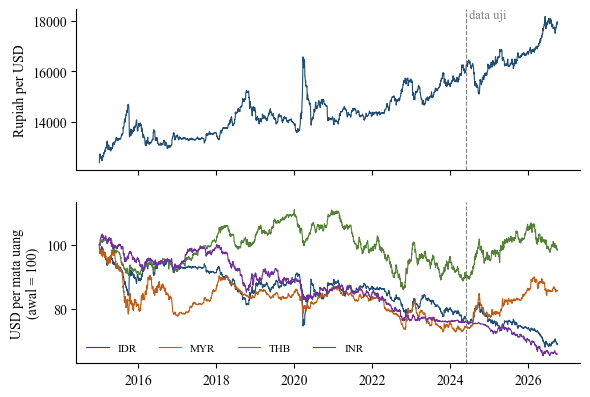

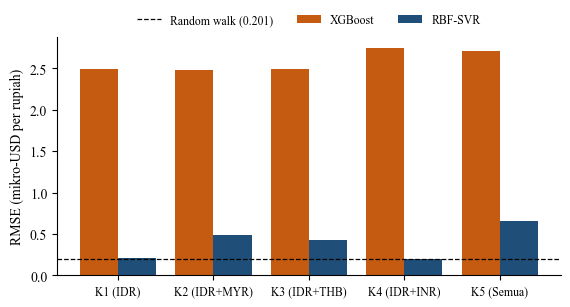

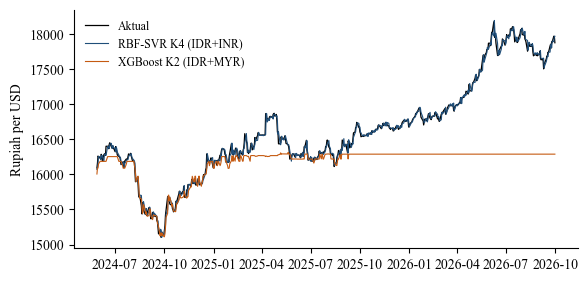

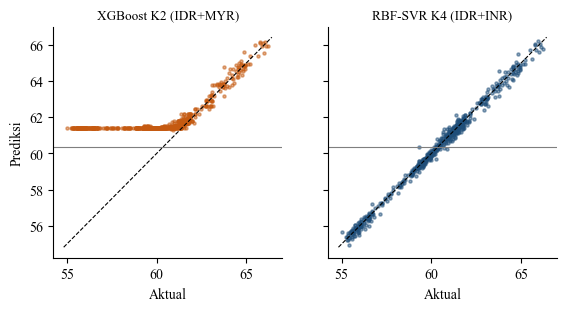

In [7]:
plt.rcParams.update({"font.family": "serif", "font.serif": ["Times New Roman"], "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "savefig.dpi": 220, "savefig.bbox": "tight"})
def simpan(fig, nama):
    # Windows kadang menolak sesaat saat PNG lama ditimpa, jadi penyimpanan diulang beberapa kali.
    for coba in range(5):
        try:
            return fig.savefig(nama)
        except OSError:
            if coba == 4:
                raise
            time.sleep(2)


BIRU, ORANYE, ABU = "#1f4e79", "#c55a11", "#7f7f7f"
info = json.load(open("hasil/info.json"))
df = pd.read_csv("hasil/data_bersih.csv", parse_dates=[0], index_col=0)
pr = pd.read_csv("hasil/prediksi.csv", parse_dates=["tanggal"]).set_index("tanggal")
res = pd.read_csv("hasil/hasil_utama.csv")
batas = pd.Timestamp(info["test_start"])

# Gambar 1: rupiah per USD dan indeks kelima mata uang
fig, ax = plt.subplots(2, 1, figsize=(6.5, 4.6), sharex=True)
ax[0].plot(1 / df.IDR, color=BIRU, lw=.8)
ax[0].axvline(batas, color=ABU, ls="--", lw=.8)
ax[0].text(batas, ax[0].get_ylim()[1], " data uji", va="top", fontsize=9, color=ABU)
ax[0].set_ylabel("Rupiah per USD")
for c, col in zip(df.columns, [BIRU, ORANYE, "#548235", "#7030a0", ABU]):
    ax[1].plot(df[c] / df[c].iloc[0] * 100, lw=.8, color=col, label=c)
ax[1].axvline(batas, color=ABU, ls="--", lw=.8)
ax[1].set_ylabel("USD per mata uang\n(awal = 100)")
ax[1].legend(ncol=5, frameon=False, fontsize=8, loc="lower left")
simpan(fig, "hasil/gambar1_kurs.png"); plt.show()

# Gambar 2: RMSE per konfigurasi
m = res[res.algo != "Random walk"]
rw = res[res.algo == "Random walk"].RMSE.iloc[0]
ks = list(dict.fromkeys(m.konfigurasi))
x = np.arange(len(ks))
fig, ax = plt.subplots(figsize=(6.5, 3.1))
ax.bar(x - .2, m[m.algo == "XGBoost"].set_index("konfigurasi").loc[ks].RMSE, .4, color=ORANYE, label="XGBoost")
ax.bar(x + .2, m[m.algo == "SVR"].set_index("konfigurasi").loc[ks].RMSE, .4, color=BIRU, label="RBF-SVR")
ax.axhline(rw, color="k", ls="--", lw=.9, label=f"Random walk ({rw:.3f})")
ax.set_xticks(x, ks, fontsize=8.5)
ax.set_ylabel("RMSE (mikro-USD per rupiah)")
ax.legend(frameon=False, fontsize=8.5, ncol=3, loc="lower center", bbox_to_anchor=(.5, 1))
simpan(fig, "hasil/gambar2_rmse.png"); plt.show()

# Gambar 3: aktual vs prediksi model terbaik tiap algoritma (dalam rupiah per USD)
best = {a: m[m.algo == a].sort_values("RMSE").konfigurasi.iloc[0] for a in ["XGBoost", "SVR"]}
fig, ax = plt.subplots(figsize=(6.5, 3.1))
ax.plot(1e6 / pr.aktual, color="k", lw=.9, label="Aktual")
ax.plot(1e6 / pr[f"SVR|{best['SVR']}"], color=BIRU, lw=.8, label=f"RBF-SVR {best['SVR']}")
ax.plot(1e6 / pr[f"XGBoost|{best['XGBoost']}"], color=ORANYE, lw=.8, label=f"XGBoost {best['XGBoost']}")
ax.set_ylabel("Rupiah per USD")
ax.legend(frameon=False, fontsize=8.5)
simpan(fig, "hasil/gambar3_prediksi.png"); plt.show()

# Gambar 4: sebar aktual vs prediksi, memperlihatkan batas ekstrapolasi
fig, ax = plt.subplots(1, 2, figsize=(6.5, 3.0), sharex=True, sharey=True)
lo = info["train_y_min"]
for a, nama, col, k in zip(ax, ["XGBoost", "RBF-SVR"], [ORANYE, BIRU], ["XGBoost", "SVR"]):
    a.scatter(pr.aktual, pr[f"{k}|{best[k]}"], s=5, color=col, alpha=.5)
    lim = [pr.aktual.min() - .2, pr.aktual.max() + .2]
    a.plot(lim, lim, "k--", lw=.8)
    a.axhline(lo, color=ABU, lw=.8)
    a.set_title(f"{nama} {best[k]}", fontsize=9.5)
    a.set_xlabel("Aktual")
ax[0].set_ylabel("Prediksi")
simpan(fig, "hasil/gambar4_ekstrapolasi.png"); plt.show()

## 7. Analisis lanjutan

Rentang harga, akurasi arah, dan perubahan hubungan antarmata uang.

In [8]:
info = json.load(open("hasil/info.json"))
p = pd.read_csv("hasil/prediksi.csv", parse_dates=["tanggal"]).set_index("tanggal")
y, rw = p.aktual, p.RW
inside = y >= info["train_y_min"]
rows = []
h = pd.read_csv("hasil/hasil_utama.csv")
terbaik = [f"{a}|{h[h.algo == a].sort_values('RMSE').konfigurasi.iloc[0]}" for a in ["XGBoost", "SVR"]]
for k in dict.fromkeys(["RW", "XGBoost|K1 (IDR)", "SVR|K1 (IDR)", *terbaik, "XGBoost|K5 (Semua)", "SVR|K5 (Semua)"]):
    e = p[k] - y
    rows.append({"model": k, "RMSE_dalam": (e[inside]**2).mean()**.5, "RMSE_luar": (e[~inside]**2).mean()**.5,
                 "ME": e.mean(), "ME_luar": e[~inside].mean(), "pred_min": p[k].min(), "pred_max": p[k].max()})
pd.DataFrame(rows).to_csv("hasil/rentang_harga.csv", index=False)
print(pd.DataFrame(rows).round(3).to_string()); print("dalam", inside.sum(), "luar", (~inside).sum())
print("awal uji Rp/USD", round(1e6/y.iloc[0]), "akhir", round(1e6/y.iloc[-1]), "maks", round(1e6/y.min()), y.idxmin().date(), "train maks Rp", round(1e6/info["train_y_min"]))
print("first outside", y[~inside].index[0].date())
nz = y != rw  # hari tanpa perubahan kurs tidak memiliki arah
n = int(nz.sum())
arah = []
for k in [c for c in p.columns if c not in ("aktual", "RW")]:
    hit = int((np.sign(y-rw) == np.sign(p[k]-rw))[nz].sum())
    arah.append({"model": k, "benar": hit, "hari": n, "DA": hit/n*100, "p": stats.binomtest(hit, n, .5).pvalue})
pd.DataFrame(arah).to_csv("hasil/akurasi_arah.csv", index=False)
print(pd.DataFrame(arah).round(4).to_string())
print("zero changes", int((y == rw).sum()))

# Perubahan hubungan antarmata uang: korelasi level dan return, latih vs uji
df = pd.read_csv("hasil/data_bersih.csv", parse_dates=[0], index_col=0)
b = pd.Timestamp(info["test_start"])
tr, te = df[df.index < b], df[df.index >= b]
r = np.log(df).diff() * 100
rows = [{"mata_uang": c, "lvl_latih": tr.IDR.corr(tr[c]), "lvl_uji": te.IDR.corr(te[c]), "ret_latih": r.IDR[r.index < b].corr(r[c][r.index < b]),
         "ret_uji": r.IDR[r.index >= b].corr(r[c][r.index >= b]), "chg_uji_pct": (te[c].iloc[-1] / te[c].iloc[0] - 1) * 100} for c in df]
pd.DataFrame(rows).to_csv("hasil/stabilitas_hubungan.csv", index=False)
print(pd.DataFrame(rows).round(3).to_string())

                  model  RMSE_dalam  RMSE_luar     ME  ME_luar  pred_min  pred_max
0                    RW       0.220      0.175  0.010    0.020    55.015    66.220
1      XGBoost|K1 (IDR)       0.464      3.664  1.633    3.239    61.412    66.114
2          SVR|K1 (IDR)       0.220      0.196  0.047    0.087    55.176    66.230
3  XGBoost|K2 (IDR+MYR)       0.459      3.641  1.620    3.215    61.299    66.178
4      SVR|K4 (IDR+INR)       0.221      0.176 -0.003    0.001    54.956    66.213
5    XGBoost|K5 (Semua)       0.646      3.955  1.877    3.553    61.678    66.081
6        SVR|K5 (Semua)       0.305      0.912  0.483    0.852    56.354    66.247
dalam 334 luar 278
awal uji Rp/USD 16091 akhir 17878 maks 18177 2026-06-08 train maks Rp 16576
first outside 2025-02-28
                  model  benar  hari       DA       p
0      XGBoost|K1 (IDR)    262   546  47.9853  0.3688
1  XGBoost|K2 (IDR+MYR)    270   546  49.4505  0.8306
2  XGBoost|K3 (IDR+THB)    278   546  50.9158  0.7002


## 8. Waktu pencatatan

Korelasi return antarhari pada Investing.com dan ECB. Pola satu arah menandakan perbedaan jam pencatatan.

In [9]:
baris = []
for nama, d in [("Investing", muat("Investing") if SUMBER == "Investing" else None), ("ECB", load_ecb().dropna())]:
    if d is None:
        continue
    r = np.log(d).diff().dropna()
    for c in CUR[1:]:
        baris.append({"sumber": nama, "mata_uang": c, "sama": r.IDR.corr(r[c]), "lain_ke_idr": r.IDR.corr(r[c].shift(1)),
                      "idr_ke_lain": r[c].corr(r.IDR.shift(1))})
    print(nama, "return nol", (r == 0).sum().to_dict())
pd.DataFrame(baris).to_csv("hasil/korelasi_antarhari.csv", index=False)
if SUMBER == "Investing":
    a, b = np.log(muat("Investing")).diff().IDR, np.log(load_ecb()).diff().IDR
    print("IDR Investing vs ECB hari sama", round(a.corr(b), 3), "ECB kemarin", round(a.corr(b.shift(1)), 3))
pd.DataFrame(baris).round(3)

IDR n 3065 2015-01-01 2026-09-30 faktor 1000.0 dev median % 0.09 p99 % 1.063
MYR n 3065 2015-01-01 2026-09-30 faktor 1.0 dev median % 0.015 p99 % 0.639
THB n 3065 2015-01-01 2026-09-30 faktor 1.0 dev median % 0.117 p99 % 0.759
INR n 3065 2015-01-01 2026-09-30 faktor 100.0 dev median % 0.058 p99 % 0.425
Investing return nol {'IDR': 319, 'MYR': 398, 'THB': 578, 'INR': 80}
ECB return nol {'IDR': 2, 'MYR': 1, 'THB': 0, 'INR': 1}


IDR n 3065 2015-01-01 2026-09-30 faktor 1000.0 dev median % 0.09 p99 % 1.063
MYR n 3065 2015-01-01 2026-09-30 faktor 1.0 dev median % 0.015 p99 % 0.639
THB n 3065 2015-01-01 2026-09-30 faktor 1.0 dev median % 0.117 p99 % 0.759
INR n 3065 2015-01-01 2026-09-30 faktor 100.0 dev median % 0.058 p99 % 0.425


IDR Investing vs ECB hari sama 0.754 ECB kemarin 0.202


,sumber,mata_uang,sama,lain_ke_idr,idr_ke_lain
0,Investing,MYR,0.509,0.055,0.085
1,Investing,THB,0.226,0.259,-0.019
2,Investing,INR,0.247,0.217,-0.028
3,ECB,MYR,0.504,-0.023,0.077
4,ECB,THB,0.470,-0.013,-0.008
5,ECB,INR,0.465,-0.033,-0.038


## 9. Uji ketahanan

Pembagian 70:30 dan 90:10, target *log-return*, dan data Yahoo. Jika sumber utama Investing.com, ECB ikut menjadi pembanding.

In [10]:
def job(sumber, frac, target):
    df = muat(sumber).dropna()
    out = run(df, sumber, frac=frac, target=target, svr_grid=SVR_GRID_RETURN if target == "return" else SVR_GRID)
    r = out[0]
    p, y = out[1], out[3]
    r["DM_vsRW"] = [dm(y, p[f"{a}|{k}"], p["RW"])[0] if a != "Random walk" else float("nan") for a, k in zip(r.algo, r.konfigurasi)]
    r["p_vsRW"] = [dm(y, p[f"{a}|{k}"], p["RW"])[1] if a != "Random walk" else float("nan") for a, k in zip(r.algo, r.konfigurasi)]
    r["n_obs"] = len(df)
    m = r.algo != "Random walk"
    r.loc[m, "p_holm"] = multipletests(r.loc[m, "p_vsRW"], method="holm")[1]  # koreksi atas sepuluh perbandingan
    return r


varian = [(SUMBER, .8, "return"), (SUMBER, .7, "level"), (SUMBER, .9, "level"), ("Yahoo", .8, "level")]
if SUMBER != "ECB":
    varian += [("ECB", .8, "level"), ("ECB", .8, "return")]
with parallel_config(backend="loky", inner_max_num_threads=2):
    hasil = Parallel(n_jobs=4)(delayed(job)(*a) for a in varian)
pd.concat(hasil).to_csv("hasil/sensitivitas.csv", index=False)
print("SELESAI")

SELESAI


## 10. Teks artikel

Isi artikel dan daftar pustaka. Angka di teks ditulis dari hasil sumber `NASKAH_SUMBER`.

In [11]:
JUDUL = "Prediksi Kurs Rupiah terhadap Dolar AS Menggunakan Machine Learning Berdasarkan Riwayat Kurs dan Mata Uang Negara Berkembang Asia"

ABSTRAK = ("Prediksi kurs rupiah sering dilaporkan akurat, tetapi banyak studi tidak mengujinya terhadap tolok ukur paling sederhana, "
"yaitu *random walk*. Penelitian ini menguji apakah riwayat kurs ringgit Malaysia, baht Thailand, dan rupee India "
"meningkatkan prediksi satu hari ke depan IDR/USD dibandingkan riwayat rupiah saja. XGBoost dan *Support Vector Regression* kernel RBF "
"dilatih pada lima konfigurasi prediktor berbasis lima lag, sehingga menghasilkan sepuluh model, memakai 3.065 observasi harian Investing.com "
"periode Januari 2015 sampai September 2026 dengan pembagian kronologis 80:20. Kinerja dinilai dengan MAE, RMSE, MAPE, "
"R², dan uji Diebold-Mariano. Tidak satu pun model mengalahkan *random walk* (RMSE 0,2008 mikro-USD per rupiah; MAE sekitar Rp40). "
"Model terbaik, RBF-SVR dengan tambahan rupee India, mencapai RMSE 0,2018; lebih akurat secara signifikan daripada RBF-SVR berbasis "
"rupiah saja, tetapi tidak berbeda signifikan dari *random walk* (*p* = 0,516). Ringgit dan baht justru memperburuk prediksi karena hubungan levelnya "
"dengan rupiah berbalik pada periode uji. XGBoost gagal berekstrapolasi saat rupiah menembus rekor pelemahan data latih, sehingga galatnya "
"sekitar dua belas kali lipat, tetapi masalah ini hilang saat target diubah menjadi *log-return*. Pada target itu RBF-SVR dengan baht tampak mengalahkan *random walk* (*p* = 0,015), tetapi hasil tersebut gugur setelah koreksi Holm dan konsisten dengan perbedaan waktu pencatatan antarmata uang pada sumber data. Kontribusi penelitian ini adalah bukti bahwa informasi mata uang Asia hanya bermanfaat sebatas hubungannya "
"stabil, serta peringatan metodologis mengenai pemodelan level kurs dengan model berbasis pohon dan mengenai sinkronisasi waktu data harian.")

KATA_KUNCI = "kurs rupiah; prediksi nilai tukar; XGBoost; Support Vector Regression; random walk"

ABSTRACT = ("Rupiah exchange rate forecasts are often reported as accurate, yet many studies never test them against the simplest benchmark, "
"the random walk. This study asks whether the histories of the Malaysian ringgit, Thai baht, and Indian rupee improve "
"one-day-ahead IDR/USD forecasts beyond the rupiah's own history. XGBoost and RBF-kernel Support Vector Regression were trained on five "
"five-lag predictor configurations, giving ten models, using 3,065 daily Investing.com observations from January 2015 to "
"September 2026 with a chronological 80:20 split. Performance was assessed with MAE, RMSE, MAPE, R², and the Diebold-Mariano test. No "
"model beat the random walk (RMSE 0.2008 micro-USD per rupiah; MAE about IDR 40). The best model, RBF-SVR with the Indian rupee, reached an "
"RMSE of 0.2018 and was significantly more accurate than rupiah-only RBF-SVR, yet was not significantly different from the random walk (p = .516). The ringgit "
"and baht degraded forecasts because their level relationship with the rupiah reversed during the test period. XGBoost could not extrapolate "
"once the rupiah passed its training-sample record low, producing errors roughly twelve times larger, a problem that disappeared once the target became the log-return. With that target, RBF-SVR with the baht appeared to beat the random walk (p = .015), but the result did not survive Holm correction and is consistent with differing recording times across currencies in the data source. The study contributes evidence that Asian "
"currency information helps only as far as its relationship remains stable, along with a methodological warning about modelling exchange-rate "
"levels with tree-based learners and about the synchronisation of daily data.")
KEYWORDS = "rupiah exchange rate; exchange rate forecasting; XGBoost; Support Vector Regression; random walk"

P1 = [
("h1", "1. Pendahuluan"),
("p", "Pada 8 Juni 2026 rupiah mencapai sekitar Rp18.177 per dolar AS, titik terlemah dalam data penelitian ini, dari kisaran Rp12.400 pada awal 2015. Pergerakan sebesar itu memengaruhi biaya impor, beban utang valuta asing, dan perencanaan keuangan perusahaan, sehingga model prediksi kurs banyak diminati. Rupiah juga bukan mata uang yang bergerak sendirian. Studi limpahan guncangan menunjukkan bahwa kawasan Asia berkembang menerima transmisi dari pasar global, dengan intensitas terbesar pada masa COVID-19 (Azis dkk., 2021). Devpura (2021) mencatat bahwa sekitar 22% varians galat peramalan return kurs enam belas mata uang Asia berasal dari limpahan antarmata uang. Rasbin dkk. (2021) menambahkan bahwa rupiah berada di bawah nilai keseimbangannya pada sebagian besar periode yang mereka amati. Fakta-fakta ini memberi alasan untuk menduga bahwa kurs mata uang tetangga menyimpan informasi tentang arah rupiah."),
("p", "Masalahnya, memprediksi kurs dikenal sangat sulit. Meese dan Rogoff (1983) menunjukkan bahwa model struktural tidak mampu mengalahkan *random walk* di luar sampel, dan telaah Rossi (2013) menegaskan bahwa keterprediksian kurs bergantung pada prediktor, horizon, model, dan periode evaluasi. Karena itu, angka kesalahan yang tampak kecil belum membuktikan apa pun. Kurs harian sangat persisten, sehingga model yang sekadar mengulang nilai kemarin pun sudah menghasilkan MAPE rendah dan R² mendekati satu. Sebuah model baru benar-benar berguna jika ia lebih baik daripada tebakan sederhana tersebut."),
("p", "Literatur *machine learning* untuk kurs berkembang ke dua arah. Arah pertama mengusulkan arsitektur yang makin kompleks, seperti CNN-TLSTM untuk USD/CNY (J. Wang dkk., 2021), LSTM berbasis atensi untuk EUR/USD (Ghahremani & Nguyen, 2025), hibrida CNN-BiLSTM di pasar Rwanda (Nsengiyumva dkk., 2025), dan kombinasi BiLSTM dengan *random forest* (Cui & Jiang, 2026). Studi-studi ini umumnya membandingkan model usulan dengan model pembelajaran lain, dan sering melaporkan keunggulan arsitektur baru. Arah kedua lebih berhati-hati dan menguji model terhadap *random walk* atau menelaah pemilihan prediktor. Pfahler (2021) menemukan daya prediksi arah yang signifikan pada data bulanan sepuluh pasangan mata uang OECD dengan jaringan saraf dan XGBoost. Yu dkk. (2024) meneliti pemilihan prediktor renminbi, Wada (2022) memanfaatkan regresi pita spektral dan LASSO, sedangkan de Mendonça dkk. (2025) menemukan bahwa sebagian model fundamental berguna di Brasil pada kondisi tertentu. Pincheira dkk. (2022) bahkan mengembangkan uji khusus terhadap hipotesis *random walk*. Pelajaran dari arah kedua ini adalah bahwa keunggulan selalu bersyarat."),
("p", "Pola yang sama terlihat pada penelitian rupiah. Firdausanti dkk. (2025) melaporkan LSTM berbasis atensi lebih akurat daripada MS-GARCH. Syahzaqi dkk. (2026) memakai hibrida ARIMA-SVR pada 150 observasi mingguan, dan Akbar (2026) membandingkan VECM dengan SVR, *random forest*, dan LSTM memakai variabel makro bulanan. Fahlevi dan Sinduningrum (2026) membandingkan XGBoost dan LSTM dengan fitur turunan rupiah. Cahyani dkk. (2026) menambahkan indeks risiko geopolitik dan menemukan R² negatif pada XGBoost. Temuan paling menantang datang dari Mahrom dkk. (2026): pada JISDOR 2021-2026, *persistence* justru mengalahkan LSTM, Bi-LSTM, dan Transformer secara signifikan, dan variabel eksternal (IHSG, minyak Brent, inflasi) tidak menambah akurasi. Tabel 1 merangkum studi-studi yang paling dekat dengan penelitian ini."),
("table", "t_lit"),
("p", "Dari Tabel 1 tampak celah yang spesifik. Variabel eksternal yang diuji pada studi rupiah kebanyakan berupa saham, komoditas, risiko geopolitik, atau makroekonomi. Padahal literatur limpahan menunjukkan keterkaitan antarmata uang Asia, dan Rehman dkk. (2022) menemukan ketergantungan terarah antarkurs negara berkembang yang terlihat pada lag 1 lalu memudar pada lag lebih panjang. Temuan itu menyiratkan bahwa lag mata uang lain mungkin bernilai prediktif, tetapi studi limpahan menjelaskan keterkaitan, bukan akurasi prediksi di luar sampel. Fundama dkk. (2026) memang membandingkan SVR dan XGBoost dengan uji Diebold-Mariano, tetapi untuk rand Afrika Selatan. Dalam penelusuran kami di Crossref dan OpenAlex (November 2026, publikasi 2021-2026, kata kunci gabungan *rupiah*, *exchange rate forecasting*, *XGBoost*, *support vector regression*, *ASEAN*, dan *cross-currency*), kami tidak menemukan studi yang menguji lag MYR, THB, dan INR sebagai prediktor IDR/USD satu per satu dan bersamaan pada kedua algoritma tersebut terhadap *random walk*. Studi terdekat adalah Mahrom dkk. (2026) dan Fundama dkk. (2026). Pernyataan ini terbatas pada basis data dan kata kunci tersebut, bukan klaim bahwa studi serupa tidak ada sama sekali."),
("p", "Penelitian ini menjawab celah tersebut dengan eksperimen komputasional yang sengaja sederhana. XGBoost dipilih karena populer dan mampu menangkap interaksi nonlinier (Chen & Guestrin, 2016). RBF-SVR dipilih karena mewakili keluarga kernel yang telah lama dipakai untuk regresi (Drucker dkk., 1997) dan juga diterapkan pada kurs (Khoa & Huynh, 2022). Dengan masukan lag yang sama, perbedaan hasil dapat dibaca sebagai perbedaan algoritma dan informasi prediktor, bukan perbedaan rekayasa fitur."),
("p", "Tujuan penelitian ini ada tiga. Pertama, membandingkan kinerja XGBoost dan RBF-SVR dalam memprediksi IDR/USD satu observasi ke depan. Kedua, mengidentifikasi konfigurasi prediktor terbaik dari lima konfigurasi masukan. Ketiga, menilai apakah model mana pun mengungguli *random walk*. Kontribusi yang ditawarkan bersifat empiris dan metodologis: bukti tentang nilai prediktif mata uang Asia bagi rupiah, penjelasan mengapa nilainya berbeda antarmata uang, serta dokumentasi kegagalan ekstrapolasi yang dapat terjadi tanpa terlihat bila model hanya dinilai dari MAPE."),

("h1", "2. Metode"),
("h2", "2.1 Desain Penelitian"),
("p", "Penelitian ini memakai pendekatan kuantitatif dengan eksperimen komputasional pada data deret waktu. Desain ini dipilih karena pertanyaan penelitiannya bersifat prediktif: yang diukur adalah akurasi di luar sampel, bukan hubungan kausal antarmata uang. Rancangan faktorial 2 × 5 (dua algoritma, lima konfigurasi) menghasilkan sepuluh model, ditambah *random walk* sebagai tolok ukur."),
("p", 'Pelaksanaan penelitian berbeda dari proposal kelompok dalam dua hal, dan keduanya dilaporkan terbuka. Pertama, proposal merencanakan empat mata uang prediktor, tetapi peso Filipina dikeluarkan karena riwayatnya di Investing.com baru tersedia sejak Juli 2018, sehingga konfigurasi berkurang dari enam menjadi lima. Kedua, *random walk* dan uji Diebold-Mariano ditambahkan karena panduan penulisan meminta perbandingan dengan metode pembanding yang relevan dan klaim keunggulan harus didukung bukti.'),
("h2", "2.2 Sumber Data dan Sampel"),
("p", 'Data berupa harga penutupan harian IDR/USD, MYR/USD, THB/USD, dan INR/USD dari halaman data historis Investing.com (Investing.com, 2026), periode 1 Januari 2015 sampai 30 September 2026. Berkas diunduh secara manual dalam format CSV. Investing.com menampilkan IDR/USD per 1.000 rupiah dan INR/USD per 100 rupee, sehingga keduanya disetarakan menjadi nilai dolar AS untuk satu unit mata uang, sesuai definisi IDR/USD pada proposal. Karena angkanya sangat kecil (sekitar 0,00006), target dikalikan 10⁶ dan dilaporkan dalam satuan mikro-USD per rupiah. Sebagai gambaran, 62,5 mikro-USD setara Rp16.000 per dolar AS.'),
("p", 'Kualitas data diperiksa dengan membandingkannya terhadap kurs referensi Bank Sentral Eropa (European Central Bank, 2026), yang dihitung sebagai kurs silang melalui euro. Deviasi median Investing.com terhadap ECB kecil (0,02% sampai 0,12%), dengan persentil ke-99 di bawah 1,1%. ECB kemudian dipakai sebagai pembanding pada uji ketahanan. Data Yahoo Finance juga diperiksa dan menunjukkan lonjakan yang tidak wajar, misalnya perubahan USD/IDR sekitar -5,8% dan +7,2% pada 26 dan 27 Desember 2024 yang langsung berbalik keesokan harinya, sehingga Yahoo Finance hanya dipakai pada uji ketahanan setelah lonjakan semacam itu dibuang.'),
("p", 'Hari Sabtu dan Minggu yang kadang muncul pada berkas Investing.com dibuang. Seluruh 3.065 observasi hari kerja lengkap untuk keempat seri, sehingga tidak diperlukan imputasi. Hilangnya lima observasi pertama untuk pembentukan lag menyisakan 3.060 sampel. Pembagian kronologis 80:20 menghasilkan 2.448 sampel latih (sampai 27 Mei 2024) dan 612 sampel uji (28 Mei 2024 sampai 30 September 2026).'),
("h2", "2.3 Variabel dan Konfigurasi Prediktor"),
("p", "Variabel target adalah nilai IDR/USD pada hari *t*. Variabel prediktor adalah lima lag terakhir (*t*-1 sampai *t*-5) dari kurs yang dipilih. Jumlah lima lag mengikuti proposal dan mencakup kira-kira satu minggu perdagangan. Tidak ada nilai pada hari *t* yang masuk ke prediktor. Lima konfigurasi disajikan pada Tabel 2."),
("table", "t_konf"),
("h2", "2.4 Prosedur Eksperimen"),
("p", "Eksperimen dijalankan dengan Python, scikit-learn, dan XGBoost, melalui lima tahap berurutan. **Pertama**, data dibaca, dibersihkan, dan diselaraskan menurut tanggal. **Kedua**, matriks lag dibentuk untuk tiap konfigurasi. **Ketiga**, data dipotong secara kronologis tanpa pengacakan. **Keempat**, nilai masukan dan target distandarkan dengan rerata dan simpangan baku yang dihitung hanya dari data latih, lalu transformasi yang sama diterapkan pada data uji. **Kelima**, hiperparameter dipilih, model dilatih ulang pada seluruh data latih, dan prediksi dibuat untuk data uji. Prediksi bersifat satu langkah ke depan: lag yang dipakai adalah nilai aktual yang sudah terbit, sedangkan parameter model tetap sejak akhir data latih. Langkah ini mencegah kebocoran informasi masa depan, yang menjadi perhatian utama dalam validasi deret waktu."),
("h2", "2.5 Algoritma dan Pemilihan Hiperparameter"),
("p", "XGBoost membangun ansambel pohon regresi secara bertahap, setiap pohon baru mengoreksi residu model sebelumnya (Chen & Guestrin, 2016). Prediksinya berupa jumlah nilai daun, sehingga keluarannya terbatas pada kisaran yang dipelajari dari data latih. RBF-SVR mencari fungsi yang mengabaikan galat dalam tabung selebar ε dan memakai kernel K(x, x′) = exp(-γ‖x - x′‖²) untuk memetakan pola nonlinier (Drucker dkk., 1997). Parameter C mengatur besarnya penalti galat, sedangkan γ mengatur jangkauan pengaruh tiap vektor pendukung."),
("p", "Hiperparameter dipilih dengan pencarian grid dan validasi silang *expanding window* lima lipatan (TimeSeriesSplit) di dalam data latih, dengan MAE sebagai kriteria. Grid untuk kedua algoritma terdapat pada Tabel 3. Data uji tidak terlibat dalam pemilihan ini. XGBoost memakai *subsample* dan *colsample_bytree* 0,8 serta *random seed* 42."),
("table", "t_grid"),
("h2", "2.6 Evaluasi Model"),
("p", "Kinerja diukur pada data uji dengan empat metrik sesuai proposal: MAE, RMSE, MAPE, dan R². Dua ukuran ditambahkan. U (rasio Theil) adalah RMSE model dibagi RMSE *random walk*; nilai di bawah 1 berarti model mengalahkan tolok ukur. MAE dalam rupiah dihitung setelah prediksi dikembalikan ke satuan rupiah per dolar supaya mudah ditafsirkan. Akurasi arah (DA) diukur sebagai persentase hari ketika tanda perubahan yang diprediksi sama dengan tanda perubahan aktual, lalu diuji terhadap 50% dengan uji binomial. Hari tanpa perubahan kurs tidak dihitung karena tidak memiliki arah."),
("eq", "ŷ(RW) pada hari t = y pada hari t-1"),
("p", "Signifikansi perbedaan akurasi diuji dengan uji Diebold-Mariano (Diebold & Mariano, 1995) dengan koreksi sampel kecil dari Harvey dkk. (1997) untuk horizon satu langkah. Statistik positif berarti model pertama lebih buruk daripada pembandingnya. Uji utama memakai kerugian kuadrat, dan kerugian absolut dipakai sebagai pemeriksaan. Kontribusi tiap mata uang pada konfigurasi K5 dinilai dengan kepentingan permutasi berkelompok: lima lag suatu mata uang diacak pada data uji sebanyak 30 kali, lalu kenaikan RMSE dicatat."),
("p", 'Ketahanan temuan diperiksa dengan enam variasi: rasio pembagian 70:30 dan 90:10, target berupa *log-return* yang direkonstruksi kembali ke level, data Yahoo Finance yang telah dibersihkan, serta data ECB dengan target level dan *log-return*. Varian level memakai grid yang sama dengan eksperimen utama. Varian *log-return* memakai grid SVR lebih kecil (C = 0,1 atau 1; γ = 0,001 atau 0,01; ε = 0,01 atau 0,1) karena pelatihannya jauh lebih lambat. Pada tiap variasi, nilai *p* terhadap *random walk* juga dikoreksi dengan metode Holm karena sepuluh model diuji sekaligus. Penelitian ini memakai data pasar publik tanpa subjek manusia, sehingga tidak memerlukan persetujuan etik.'),

("h1", "3. Hasil"),
("h2", "3.1 Deskripsi Data"),
("p", 'Gambar 1 memperlihatkan rupiah melemah dari sekitar Rp12.400 menjadi hampir Rp17.900 per dolar AS pada akhir periode, dengan lonjakan tajam pada Maret 2020 dan pelemahan baru sepanjang 2025-2026. Panel bawah menunjukkan bahwa setelah garis batas data uji, ringgit dan baht menguat, sementara rupiah dan rupee terus melemah. Statistik deskriptif ada pada Tabel 4.'),
("figure", "gambar1_kurs.png", "Gambar 1. Kurs rupiah per dolar AS (atas) dan indeks nilai empat mata uang terhadap dolar AS, awal periode = 100 (bawah). Garis putus-putus menandai awal data uji."),
("table", "t_desk"),
("p", 'Uji ADF tidak menolak hipotesis akar unit pada log level IDR, THB, dan INR pada taraf 5%, sedangkan seluruh seri return stasioner. MYR menjadi pengecualian dengan *p* = 0,016. Korelasi return harian rupiah pada hari yang sama adalah 0,51 dengan ringgit, 0,23 dengan baht, dan 0,25 dengan rupee. Korelasi return rupiah dengan return hari sebelumnya mata uang lain adalah 0,05 (MYR), 0,26 (THB), dan 0,22 (INR). Angka yang relatif besar ini tidak terlihat pada data ECB dan dibahas tersendiri pada Subbab 3.7.'),
("p", 'Periode uji juga menyimpan tantangan khusus. Rekor pelemahan pada data latih adalah sekitar Rp16.576 per dolar AS, sedangkan 278 dari 612 observasi uji (45,4%), mulai 28 Februari 2025, berada di luar batas itu.'),
("h2", "3.2 Kinerja Sepuluh Model"),
("p", 'Tabel 5 menyajikan hasil utama. Tidak ada model yang mengalahkan *random walk* pada metrik apa pun: semua nilai U berada di atas 1. Hasil terbaik diraih RBF-SVR K4 (IDR+INR) dengan RMSE 0,2018, hanya 0,5% di atas *random walk* (0,2008). Selisih MAE-nya setara kurang dari Rp1. RBF-SVR K1 berada di tempat kedua dengan RMSE 0,2092. Gambar 2 memperlihatkan jarak yang lebar antara kedua algoritma.'),
("table", "t_utama"),
("figure", "gambar2_rmse.png", "Gambar 2. RMSE tiap model pada data uji. Garis putus-putus menunjukkan random walk."),
("p", 'RBF-SVR lebih unggul daripada XGBoost pada kelima konfigurasi, dan selisihnya signifikan pada semua konfigurasi (statistik DM antara -13,23 dan -15,33; *p* < 0,001). Bahkan RBF-SVR terburuk (K5, RMSE 0,6546) masih jauh lebih akurat daripada XGBoost terbaik (K2, RMSE 2,4772). XGBoost menghasilkan R² negatif pada kelima konfigurasi. Hiperparameter terpilih untuk RBF-SVR seluruhnya memakai γ = 0,001, ε = 0,001, dan C bernilai 100 atau 1000, sedangkan XGBoost memilih laju belajar 0,01 dengan pohon dangkal.'),
("h2", "3.3 Pengaruh Penambahan Mata Uang"),
("p", 'Tabel 6 merangkum uji Diebold-Mariano. Pada RBF-SVR, hanya rupee India yang memperbaiki model berbasis rupiah saja, dengan statistik DM -2,73 (*p* = 0,007). Penambahan baht dan ringgit membuat model lebih buruk secara signifikan, dan RMSE naik berturut-turut menjadi 0,4217 dan 0,4845. Penggunaan seluruh mata uang (K5) juga merusak model, dengan RMSE 0,6546. Pada XGBoost, tambahan ringgit memberi perbaikan yang signifikan tetapi sangat kecil (RMSE 2,4772 berbanding 2,4933), baht tidak mengubah hasil (*p* = 0,775), sedangkan rupee dan K5 memperburuknya.'),
("table", "t_dm"),
("p", 'Terhadap *random walk*, sembilan model kalah secara signifikan. Satu-satunya pengecualian adalah RBF-SVR K4, yang tidak berbeda signifikan dari tolok ukur (statistik DM 0,65; *p* = 0,516; kerugian absolut *p* = 0,128). Akurasi arah sejalan dengan hasil itu. Nilai tertinggi 54,03% dicapai RBF-SVR K4 (295 dari 546 hari yang kursnya berubah), tetapi belum berbeda signifikan dari 50% (*p* = 0,066). Model lain berkisar antara 47,99% dan 50,92%.'),
("p", "Kepentingan permutasi pada K5 memperkuat gambaran tersebut (Tabel 7). Mengacak lag rupiah menaikkan RMSE RBF-SVR sebesar 2,82 dan XGBoost sebesar 0,51. Mengacak lag mata uang lain hampir tidak berdampak pada XGBoost. Pada RBF-SVR nilainya malah negatif, yang berarti model menjadi sedikit lebih baik ketika informasi mata uang itu dirusak. Prediksi pada dasarnya bertumpu pada riwayat rupiah sendiri."),
("table", "t_perm"),
("h2", "3.4 Kegagalan Ekstrapolasi XGBoost"),
("p", 'Gambar 3 menunjukkan penyebab buruknya XGBoost. Sampai awal 2025, prediksinya mengikuti kurs aktual dengan cukup baik. Setelah rupiah melewati kisaran yang pernah dilihat pada data latih, prediksi XGBoost berhenti di sekitar Rp16.300, sementara kurs aktual terus naik melewati Rp18.000. RBF-SVR K4 tetap menempel pada kurs aktual sepanjang periode.'),
("figure", "gambar3_prediksi.png", "Gambar 3. Kurs aktual dan prediksi model terbaik tiap algoritma pada data uji, dalam rupiah per dolar AS."),
("figure", "gambar4_ekstrapolasi.png", "Gambar 4. Sebaran nilai aktual dan prediksi (mikro-USD per rupiah). Garis putus-putus adalah prediksi sempurna; garis abu-abu mendatar adalah batas rupiah terlemah pada data latih."),
("p", 'Gambar 4 memperlihatkan pola yang sama sebagai dinding mendatar: nilai prediksi XGBoost tidak bisa turun melewati batas tertentu. Tabel 8 mengukurnya. Di dalam rentang data latih, RMSE XGBoost K2 adalah 0,459. Di luar rentang itu, RMSE melonjak menjadi 3,641, dengan galat rata-rata 3,215 yang menandakan rupiah selalu diprediksi lebih kuat daripada kenyataan. RBF-SVR K4 tidak mengalami penurunan serupa, dengan RMSE 0,221 di dalam rentang dan 0,176 di luar rentang.'),
("table", "t_rentang"),
("h2", "3.5 Stabilitas Hubungan Antarmata Uang"),
("p", 'Peringkat mata uang pada Tabel 5 sejalan dengan perubahan hubungan level pada Tabel 9. Korelasi level IDR/USD dengan INR/USD hampir tidak berubah (0,899 menjadi 0,903). Sebaliknya, korelasi dengan MYR/USD berbalik dari 0,696 menjadi -0,590, dan THB/USD dari 0,159 menjadi -0,299. Selama periode uji, rupiah melemah 10,0% terhadap dolar, sementara ringgit dan baht justru menguat 15,1% dan 9,1%. Korelasi return harian antarmata uang, di sisi lain, tetap positif pada kedua periode, berkisar 0,20 sampai 0,52.'),
("table", "t_stab"),
("h2", "3.6 Uji Ketahanan"),
]

P2 = [
("h1", "4. Pembahasan"),
("h2", "4.1 Random Walk Tetap Sulit Dikalahkan"),
("p", "Temuan terpenting penelitian ini adalah bahwa sepuluh model tidak mampu mengalahkan tebakan paling sederhana secara berarti. Hasil ini konsisten dengan Meese dan Rogoff (1983) dan dengan telaah Rossi (2013), meskipun datanya jauh lebih baru dan modelnya nonlinier. Hasil ini juga sejalan dengan Mahrom dkk. (2026), yang menemukan *persistence* mengungguli LSTM, Bi-LSTM, dan Transformer pada JISDOR. Dua studi dengan data, periode, dan algoritma berbeda tiba pada kesimpulan yang serupa, sehingga kecil kemungkinan temuan ini hanya kebetulan pemilihan model."),
("p", 'Penjelasan yang paling mungkin bersifat statistik. Pada data ECB, yang keempat kursnya direkam pada waktu yang sama, korelasi return dengan return hari sebelumnya mendekati nol, sehingga lag hanya memberi sangat sedikit informasi tentang perubahan esok hari. Dalam kondisi itu, prediksi terbaik untuk level esok hari mendekati level hari ini. Model yang fleksibel tidak punya sinyal yang jelas untuk dipelajari, dan estimasi parameternya malah menambah galat. Tanggapan yang tepat atas hasil seperti ini bukan menyatakan *machine learning* tidak berguna, karena Pfahler (2021) dan de Mendonça dkk. (2025) menunjukkan keunggulan pada horizon atau kondisi lain. Yang perlu disimpulkan lebih sempit: untuk satu hari ke depan dengan lima lag kurs, informasi yang dapat dieksploitasi sangat tipis.'),
("p", "Temuan ini juga menjadi catatan bagi cara membaca literatur. Banyak studi pada Tabel 1 melaporkan MAPE kecil, tetapi pada penelitian ini *random walk* sendiri sudah mencapai MAPE 0,24% dan R² 0,99. Oleh karena itu, MAPE sekitar 1% atau R² 0,9 tidak dapat dianggap bukti model yang baik tanpa tolok ukur. RBF-SVR K2 sebagai contoh mencapai R² 0,961, angka yang terlihat mengesankan, padahal galatnya 2,4 kali *random walk*. Membandingkan angka antarstudi juga perlu kehati-hatian. Fahlevi dan Sinduningrum (2026) melaporkan MAE LSTM 41,41 rupiah dan akurasi arah 52,74%, sekilas mirip dengan RBF-SVR K4 di sini (Rp40,19; 54,03%), tetapi periode dan skema validasinya berbeda sehingga tidak dapat disimpulkan mana yang lebih baik."),
("h2", "4.2 Mengapa XGBoost Tertinggal"),
("p", "Keunggulan RBF-SVR atas XGBoost tidak berarti SVR selalu lebih baik untuk kurs, karena selisihnya hampir lenyap ketika target diubah menjadi *log-return*. Temuan ini lebih tepat dibaca sebagai akibat cara pemodelan. Pohon keputusan membagi ruang masukan menjadi wilayah bernilai tetap, sehingga prediksi XGBoost pada level tidak pernah keluar jauh dari nilai daun yang dipelajari (Chen & Guestrin, 2016). Ketika rupiah menembus rekor, seluruh observasi baru jatuh ke wilayah ujung yang sama, dan prediksi membeku. Ini merupakan bentuk masalah yang disorot Y. Wang dan King (2024): memprediksi nilai di luar rentang target data latih berbeda dari interpolasi biasa dan memerlukan formulasi tersendiri."),
("p", "RBF-SVR terhindar dari masalah tersebut karena hiperparameternya. Dengan γ = 0,001, jangkauan kernel kira-kira 22 satuan simpangan baku, jauh lebih lebar daripada jarak antara data uji dan data latih. Dalam rentang itu kernel berperilaku hampir linear, sehingga model pada dasarnya mengikuti lag terakhir. Pemilihan ini muncul dari validasi silang di data latih, bukan dari pengetahuan tentang data uji. Sifat ini sekaligus menjelaskan mengapa RBF-SVR terbaik mendekati *random walk*: ia menjadi versi halus dari model yang sederhana itu, bukan penemu pola baru."),
("p", "Temuan ini memperjelas hasil Cahyani dkk. (2026) yang melaporkan R² negatif untuk XGBoost pada IDR/USD. Mereka memakai data, periode, dan fitur berbeda, sehingga kami tidak dapat memastikan penyebabnya sama, tetapi mekanisme ekstrapolasi merupakan penjelasan yang patut diperiksa. Sebaliknya, Fundama dkk. (2026) menemukan selisih yang kecil antara SVR dan XGBoost pada rand. Perbedaan ini wajar: kerugian ekstrapolasi hanya muncul bila periode uji keluar dari rentang data latih, seperti pada penelitian ini. Implikasi praktisnya, model berbasis pohon sebaiknya tidak diberi level kurs pada periode bertren tanpa transformasi ke perubahan atau return. Subbab 3.6 membuktikannya: dengan target *log-return*, RMSE XGBoost langsung turun ke tingkat *random walk*. Fahlevi dan Sinduningrum (2026) juga memakai *log-return* dan pelatihan ulang berkala."),
("h2", "4.3 Nilai Mata Uang Asia Bergantung pada Stabilitas Hubungan"),
("p", 'Menjawab pertanyaan utama proposal, penambahan mata uang Asia tidak otomatis meningkatkan prediksi. Dari tiga mata uang, hanya rupee yang memperbaiki RBF-SVR, dan menggabungkan semuanya justru merusak model. Tabel 9 menawarkan penjelasan. Model level mempelajari hubungan antarlevel selama 2015-2024. Rupee terus bergerak searah dengan rupiah pada periode uji, sehingga hubungan yang dipelajari tetap berlaku. Ringgit dan baht berbalik arah, sehingga hubungan itu menyesatkan: model menerima sinyal penguatan dari ringgit ketika rupiah melemah. Besarnya kerusakan pada K2 dan K3 sejalan dengan arah pembalikan tersebut. Karena studi ini prediktif, penjelasan ini merupakan interpretasi yang konsisten dengan data, bukan hubungan kausal yang terbukti.'),
("p", "Hasil ini menempatkan literatur limpahan pada proporsi yang tepat. Devpura (2021), Azis dkk. (2021), dan Danila (2023) menunjukkan keterkaitan antarpasar yang nyata, dan korelasi return pada Tabel 9 mendukungnya. Namun, keterkaitan pada hari yang sama tidak menjadi keunggulan prediksi untuk hari esok, karena saat kurs mata uang lain tersedia, informasi yang sama umumnya sudah masuk ke kurs rupiah. Korelasi antarhari yang terlihat pada Investing.com tidak mengubah kesimpulan ini, sebab Subbab 3.7 menunjukkan bahwa korelasi itu tidak ada pada data yang direkam serentak. Rehman dkk. (2022) mencatat ketergantungan terarah pada lag 1 yang berubah menurut waktu, dan sifat berubah menurut waktu inilah yang terlihat di sini. Mahrom dkk. (2026) juga menemukan bahwa variabel eksternal tidak membantu, sehingga kedua studi menunjukkan pola yang sama pada jenis variabel berbeda: untuk horizon satu hari, riwayat rupiah sendiri sudah memuat hampir semua informasi yang bisa dimanfaatkan model."),
("p", 'Perbaikan oleh rupee pun perlu dibaca hati-hati. Peningkatan terhadap RBF-SVR K1 signifikan secara statistik, tetapi selisih MAE-nya hanya sekitar Rp2,9, dan model itu tetap tidak melewati *random walk*. K4 memang menjadi RBF-SVR terbaik pada semua variasi target level, tetapi pada target *log-return* justru menjadi yang terburuk, dengan U di atas 1. Hal ini mendukung pembacaan bahwa peringkat mata uang terutama merupakan sifat model level, yang rentan terhadap perubahan hubungan antarlevel. Rupee karena itu lebih tepat disebut prediktor yang paling tidak merugikan pada periode ini, bukan prediktor yang andal. Tidak ada jaminan hubungan INR-IDR tetap stabil, sebagaimana hubungan MYR-IDR yang kuat di data latih ternyata berbalik.'),
("h2", "4.4 Implikasi"),
("p", 'Secara metodologis, penelitian ini memberi empat anjuran bagi peneliti prediksi rupiah. Sertakan *random walk* dan uji signifikansi pada setiap evaluasi. Periksa apakah data uji keluar dari rentang data latih, dan laporkan galat secara terpisah bila itu terjadi. Periksa kualitas data lebih dahulu, sebab pemeriksaan pada Yahoo Finance menunjukkan lonjakan semu yang bisa masuk ke model tanpa disadari. Periksa pula sinkronisasi waktu antarseri bila kurs dari sumber yang sama dipakai sebagai prediktor, sebab selisih jam pencatatan dapat tampil sebagai daya prediksi.'),
("p", "Secara praktis, bagi perusahaan atau individu yang menghadapi risiko kurs, hasil ini menyarankan kewaspadaan terhadap model prediksi harian. Nilai kurs hari ini merupakan perkiraan satu hari ke depan yang sulit dikalahkan oleh model-model yang diuji. Sumber daya mungkin lebih tepat diarahkan pada pengelolaan risiko, misalnya lindung nilai, daripada mencoba menebak arah harian. Bagi otoritas moneter, kurs juga dipengaruhi intervensi, yang menurut Filardo dkk. (2022) efektif menahan penyimpangan jangka pendek di banyak negara. Faktor ini tidak terlihat oleh model berbasis lag dan bisa menjadi salah satu alasan pola harian sulit dieksploitasi, meskipun penelitian ini tidak mengujinya. Hasil penelitian ini tidak dimaksudkan sebagai dasar keputusan keuangan."),
("h2", "4.5 Keterbatasan"),
("p", 'Beberapa keterbatasan membatasi generalisasi temuan. Pertama, waktu pencatatan harga harian Investing.com tidak terdokumentasi pada berkas yang diunduh dan tampaknya tidak serentak antarmata uang, sehingga korelasi antarhari tidak dapat dibaca langsung sebagai daya prediksi yang dapat dimanfaatkan. Kedua, peso Filipina tidak diuji karena riwayatnya tidak lengkap, sehingga temuan hanya berlaku untuk tiga mata uang. Ketiga, hanya ada satu periode uji yang kebetulan mencakup tren pelemahan kuat, sehingga temuan tentang ekstrapolasi dan peringkat mata uang sangat bergantung pada periode tersebut. Parameter model juga tidak diperbarui selama periode uji, dan pelatihan ulang bergulir mungkin mengurangi kegagalan XGBoost. Keempat, nilai hiperparameter terpilih untuk RBF-SVR berada di tepi grid (γ = 0,001, ε = 0,001, dan C = 1000 pada sebagian konfigurasi), sehingga optimum sebenarnya bisa berada di luar grid. Kelima, lima lag dan horizon satu hari adalah pilihan tetap dari proposal. Lag lebih panjang, horizon lebih jauh, dan prediktor makro seperti suku bunga dan harga komoditas tidak diuji. Terakhir, varian *log-return* memakai grid SVR yang lebih kecil, dan biaya transaksi tidak diperhitungkan.'),

("h1", "5. Kesimpulan"),
("p", 'Penelitian ini menjawab tiga tujuannya sebagai berikut. RBF-SVR mengungguli XGBoost secara signifikan pada kelima konfigurasi saat memodelkan level IDR/USD. Konfigurasi terbaik adalah rupiah ditambah rupee India (K4), sedangkan ringgit, baht, dan gabungan semua mata uang memperburuk RBF-SVR. Akan tetapi, tidak ada satu pun dari sepuluh model yang mengalahkan *random walk* pada eksperimen utama. Keunggulan signifikan hanya muncul pada satu model dalam satu variasi, gugur setelah koreksi Holm, dan tidak muncul pada data ECB. Keunggulan RBF-SVR dan kerusakan akibat ringgit serta baht terikat pada pemodelan level: dengan target *log-return*, semua model hampir setara dengan *random walk*.'),
("p", "Kontribusi utamanya adalah bukti bahwa informasi mata uang Asia hanya membantu sebatas hubungan levelnya dengan rupiah tetap stabil, ditambah dokumentasi kegagalan ekstrapolasi XGBoost ketika rupiah menembus rekor data latih dan bukti bahwa perbedaan waktu pencatatan dapat tampil sebagai daya prediksi. Secara praktis, evaluasi prediksi kurs perlu selalu menyertakan tolok ukur sederhana, memeriksa pergeseran rentang data, dan tidak mengandalkan MAPE atau R² semata. Temuan ini berlaku untuk data Investing.com, satu periode uji, dan horizon satu hari."),
("p", "Penelitian lanjutan dapat mengulang eksperimen dengan JISDOR atau kurs intrahari yang tersinkron, memasukkan kembali peso Filipina bila riwayatnya tersedia, memakai evaluasi *walk-forward* dengan pelatihan ulang berkala, memperluas grid hiperparameter, serta menguji horizon lebih panjang dan prediktor makro. Pemantauan stabilitas korelasi antarmata uang secara bergulir juga patut diuji sebagai cara memilih prediktor secara adaptif."),
]

PERNYATAAN = [
("Ketersediaan Data dan Kode", "Data utama bersumber dari halaman data historis publik Investing.com, dan data pembanding dari ECB serta Yahoo Finance. Seluruh kode tersedia dalam satu berkas notebook, Prediksi_Kurs_Rupiah.ipynb, yang menyertai naskah ini bersama data mentah dan keluaran eksperimen; kode inti terdapat pada Lampiran."),
("Pernyataan Etika", "Penelitian ini memakai data pasar publik tanpa subjek manusia dan tanpa data pribadi, sehingga tidak memerlukan persetujuan etik."),
("Kontribusi Penulis", "[[Isi peran tiap anggota kelompok dengan format CRediT, misalnya Konseptualisasi, Metodologi, Perangkat Lunak, Penulisan.]]"),
("Konflik Kepentingan", "[[Konfirmasi: penulis menyatakan tidak ada konflik kepentingan.]]"),
("Pendanaan", "[[Konfirmasi: penelitian ini tidak menerima pendanaan khusus.]]"),
("Pernyataan Penggunaan AI", "Claude (Anthropic) dipakai untuk membantu menulis kode, menjalankan eksperimen, menelusuri literatur, dan menyusun draf naskah. Metadata rujukan diperiksa melalui Crossref dan OpenAlex, sedangkan isinya dibandingkan dengan abstrak yang tersedia, bukan teks lengkap. Penulis bertanggung jawab memeriksa kembali isi naskah dan rujukannya."),
]

# Klaim pada naskah hanya bertumpu pada metadata dan abstrak yang terverifikasi.
RUJUKAN = [
"Akbar, A. F. (2026). What drives the Indonesian rupiah? Evidence from VECM and machine learning. *Signifikan: Jurnal Ilmu Ekonomi, 15*(2). https://doi.org/10.15408/sjie.v15i2.51329",
"Azis, I. J., Virananda, I. G. S., & Estiko, F. I. (2021). Financial spillover in emerging Asia: A tale of three crises. *Asian Economic Papers, 20*(2), 155-170. https://doi.org/10.1162/asep_a_00806",
"Cahyani, O. I., Widians, J. A., & Agus, F. (2026). Prediksi kurs rupiah terhadap dolar dan yuan menggunakan LSTM-PSO dan XGBoost. *BIOS: Jurnal Teknologi Informasi dan Rekayasa Komputer, 8*(1), 11-20. https://doi.org/10.37148/bios.v8i1.256",
"Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*, 785-794. https://doi.org/10.1145/2939672.2939785",
"Cui, Y., & Jiang, J. (2026). Hybrid deep learning techniques integrated with machine learning for foreign exchange rate forecasting. *Electronics, 15*(7), Artikel 1463. https://doi.org/10.3390/electronics15071463",
"Danila, N. (2023). Spillover of volatility among financial instruments: ASEAN-5 and GCC market study. *PLOS ONE, 18*(10), Artikel e0292958. https://doi.org/10.1371/journal.pone.0292958",
"de Mendonça, H. F., Vereda, L., & Araújo, L. M. M. de. (2025). Fundamentals models versus random walk: Evidence from an emerging economy. *Journal of Forecasting, 44*(6), 1884-1906. https://doi.org/10.1002/for.3279",
"Devpura, N. (2021). Spillover effects of exchange rate returns in selected Asian countries. *Buletin Ekonomi Moneter dan Perbankan, 24*(1), 35-52. https://doi.org/10.21098/bemp.v24i1.1301",
"Diebold, F. X., & Mariano, R. S. (1995). Comparing predictive accuracy. *Journal of Business & Economic Statistics, 13*(3), 253-263. https://doi.org/10.1080/07350015.1995.10524599",
"Drucker, H., Burges, C. J. C., Kaufman, L., Smola, A., & Vapnik, V. (1997). Support vector regression machines. *Advances in Neural Information Processing Systems, 9*, 155-161.",
"European Central Bank. (2026). *Euro foreign exchange reference rates* [Data set]. Diakses 2 November 2026, dari https://data.ecb.europa.eu/",
"Fahlevi, S., & Sinduningrum, E. (2026). Performance comparison of XGBoost and LSTM for rupiah-USD exchange rate prediction. *MALCOM: Indonesian Journal of Machine Learning and Computer Science, 6*(4). https://doi.org/10.57152/malcom.v6i4.2809",
"Filardo, A., Gelos, G., & McGregor, T. (2022). *Exchange-rate swings and foreign currency intervention* (IMF Working Paper No. 2022/158). International Monetary Fund. https://doi.org/10.5089/9798400215322.001",
"Firdausanti, N. A., Forestryani, V., & Nuroini, H. M. (2025). Deep learning and statistical approaches for forecasting the Indonesian rupiah exchange rate. *Inferensi, 8*(2), 157. https://doi.org/10.12962/j27213862.v8i2.22709",
"Fundama, S. A., Ravele, T., Tshisikhawe, T. H., & Sigauke, C. (2026). Short-term forecasting of four rand-denominated currency markets (EUR/ZAR, CHF/ZAR, BRL/ZAR, CNY/ZAR): A comparative analysis of support vector regression, XGBoost and principal component regression. *Risks, 14*(5), Artikel 97. https://doi.org/10.3390/risks14050097",
"Ghahremani, S., & Nguyen, U. T. (2025). Prediction of foreign currency exchange rates using an attention-based long short-term memory network. *Machine Learning with Applications, 20*, Artikel 100648. https://doi.org/10.1016/j.mlwa.2025.100648",
"Harvey, D., Leybourne, S., & Newbold, P. (1997). Testing the equality of prediction mean squared errors. *International Journal of Forecasting, 13*(2), 281-291. https://doi.org/10.1016/S0169-2070(96)00719-4",
"Investing.com. (2026). *IDR/USD, MYR/USD, THB/USD, and INR/USD historical data* [Data set]. Diakses 2 November 2026, dari https://www.investing.com/currencies/idr-usd-historical-data",
"Khoa, B. T., & Huynh, T. T. (2022). Predicting exchange rate under UIRP framework with support vector regression. *Emerging Science Journal, 6*(3), 619-630. https://doi.org/10.28991/esj-2022-06-03-014",
"Mahrom, T. C., Utomo, A. P., & Adiyono, S. (2026). Comparing LSTM, Bi-LSTM, and Transformer across feature scenarios for rupiah exchange rate forecasting. *INOVTEK Polbeng - Seri Informatika, 11*(3), 1031-1041. https://doi.org/10.35314/395zyb49",
"Meese, R. A., & Rogoff, K. (1983). Empirical exchange rate models of the seventies: Do they fit out of sample? *Journal of International Economics, 14*(1-2), 3-24. https://doi.org/10.1016/0022-1996(83)90017-X",
"Nsengiyumva, E., Mung'atu, J. K., & Ruranga, C. (2025). A comparative study of multivariate CNN, BiLSTM and hybrid CNN-BiLSTM models for forecasting foreign exchange rate using deep learning. *Cogent Economics & Finance, 13*(1), Artikel 2526148. https://doi.org/10.1080/23322039.2025.2526148",
"Pfahler, J. F. (2021). Exchange rate forecasting with advanced machine learning methods. *Journal of Risk and Financial Management, 15*(1), Artikel 2. https://doi.org/10.3390/jrfm15010002",
"Pincheira, P., Hardy, N., & Bentancor, A. (2022). A simple out-of-sample test of predictability against the random walk benchmark. *Mathematics, 10*(2), Artikel 228. https://doi.org/10.3390/math10020228",
"Rasbin, R., Ikhsan, M., Gitaharie, B. Y., & Affandi, Y. (2021). Real exchange rate misalignments: The case of the Indonesian rupiah. *Buletin Ekonomi Moneter dan Perbankan, 24*(3), 441-464. https://doi.org/10.21098/bemp.v24i3.1268",
"Rehman, M. Z., Tiwari, A. K., & Samontaray, D. P. (2022). Directional predictability in foreign exchange rates of emerging markets: New evidence using a cross-quantilogram approach. *Borsa Istanbul Review, 22*(1), 145-155. https://doi.org/10.1016/j.bir.2021.03.003",
"Rossi, B. (2013). Exchange rate predictability. *Journal of Economic Literature, 51*(4), 1063-1119. https://doi.org/10.1257/jel.51.4.1063",
"Syahzaqi, I., Kusumaningrum, S. C., Hayat, N. A., & Mardianto, M. F. F. (2026). Forecasting rupiah exchange rate volatility using a hybrid ARIMA-SVR model as an early warning system to address global dynamics. *JTAM (Jurnal Teori dan Aplikasi Matematika), 10*(3), 868. https://doi.org/10.31764/jtam.v10i3.38570",
"Wada, T. (2022). Out-of-sample forecasting of foreign exchange rates: The band spectral regression and LASSO. *Journal of International Money and Finance, 128*, Artikel 102719. https://doi.org/10.1016/j.jimonfin.2022.102719",
"Wang, J., Wang, X., Li, J., & Wang, H. (2021). A prediction model of CNN-TLSTM for USD/CNY exchange rate prediction. *IEEE Access, 9*, 73346-73354. https://doi.org/10.1109/ACCESS.2021.3080459",
"Wang, Y., & King, R. D. (2024). Extrapolation is not the same as interpolation. *Machine Learning, 113*(10), 8205-8232. https://doi.org/10.1007/s10994-024-06591-2",
"Yu, X., Li, Y., & Wang, X. (2024). RMB exchange rate forecasting using machine learning methods: Can multimodel select powerful predictors? *Journal of Forecasting, 43*(3), 644-660. https://doi.org/10.1002/for.3054",
]


SENS = [
("p", "Tabel 10 merangkum enam variasi. Pada semua variasi target level, yaitu pembagian 70:30 dan 90:10, data Yahoo Finance yang telah dibersihkan (2.691 observasi), dan data ECB (3.007 observasi), tidak ada model dengan U di bawah 1. RBF-SVR K4 menjadi model terbaik pada keempatnya. Pada pembagian 90:10, jaraknya dengan *random walk* sangat tipis (RMSE 0,1682 berbanding 0,1672; DM 0,41; *p* = 0,681)."),
("table", "t_sens"),
("p", "Variasi paling informatif adalah target *log-return*. Begitu target diubah menjadi perubahan, RMSE XGBoost turun dari sekitar 2,48 menjadi 0,1963 sampai 0,2022, sehingga kegagalan pada Subbab 3.4 memang berasal dari pemodelan level. Delapan dari sepuluh model mencapai U di bawah 1. Model terbaik adalah RBF-SVR K3 (IDR+THB) dengan RMSE 0,1960 (U = 0,976), yang secara nominal signifikan lebih baik daripada *random walk* (DM -2,44; *p* = 0,015). Inilah satu-satunya hasil seperti itu dalam seluruh eksperimen, dan hasil tersebut tidak bertahan setelah koreksi Holm atas sepuluh perbandingan (*p* = 0,150). Jarak antarkonfigurasi juga mengecil, dengan RMSE RBF-SVR berkisar 0,1960 sampai 0,2015."),
("p", "Pada data ECB, keunggulan itu tidak muncul. Dengan target *log-return*, RMSE seluruh model berkisar 0,2316 sampai 0,2333 terhadap *random walk* 0,2325, tidak ada yang signifikan (seluruh *p* > 0,11), dan RBF-SVR K3 tidak lebih baik daripada RBF-SVR K1. Kesimpulan bahwa tidak ada model yang secara meyakinkan mengalahkan *random walk* karena itu bertahan pada semua variasi setelah koreksi Holm."),
("h2", "3.7 Waktu Pencatatan Data"),
("p", "Hasil baht pada target *log-return* perlu diperiksa karena sumbernya terlihat pada data. Tabel 11 membandingkan korelasi return Investing.com dan ECB. Pada ECB, korelasi rupiah dengan mata uang lain pada hari yang sama berkisar 0,47 sampai 0,50, dan korelasi dengan hari sebelumnya mendekati nol. Pada Investing.com, korelasi baht dan rupee pada hari yang sama turun menjadi 0,23 dan 0,25, sedangkan korelasi baht dan rupee kemarin dengan rupiah hari ini naik menjadi 0,26 dan 0,22. Arah sebaliknya tetap mendekati nol."),
("table", "t_lag"),
("p", "Pola satu arah ini konsisten dengan perbedaan waktu pencatatan, bukan dengan daya prediksi yang sebenarnya: sebagian pergerakan yang pada mata uang lain sudah tercatat hari ini baru tercatat pada rupiah keesokan harinya. Tanda lain mendukung pembacaan tersebut. Return Investing.com untuk rupiah berkorelasi 0,75 dengan return ECB hari yang sama dan 0,20 dengan return ECB hari sebelumnya, serta return nol tercatat pada 319 hari untuk IDR dan 578 hari untuk THB, dibandingkan paling banyak 2 hari pada ECB. Penelitian ini tidak dapat memastikan jam pencatatan tiap seri, sehingga penjelasan ini tetap merupakan dugaan yang didukung data."),
]

## 11. Rakit artikel Word

Artikel hanya dirakit jika sumber data sama dengan sumber yang dipakai saat teks ditulis, supaya angka di teks tidak salah.

In [12]:
from docx import Document
from docx.enum.table import WD_TABLE_ALIGNMENT
from docx.enum.text import WD_ALIGN_PARAGRAPH, WD_COLOR_INDEX, WD_LINE_SPACING
from docx.oxml import OxmlElement
from docx.oxml.ns import qn
from docx.shared import Cm, Pt

KELUARAN = "../Artikel_Prediksi_Kurs_Rupiah_Kelompok2.docx"
d = Document()
s = d.sections[0]
s.page_width, s.page_height = Cm(21), Cm(29.7)
s.left_margin = s.right_margin = s.top_margin = s.bottom_margin = Cm(2.54)
st = d.styles["Normal"]
st.font.name = "Times New Roman"
st.font.size = Pt(12)
st.element.rPr.rFonts.set(qn("w:eastAsia"), "Times New Roman")
for nama, uk in [("Heading 1", 13), ("Heading 2", 12)]:
    h = d.styles[nama]
    h.font.name = "Times New Roman"
    h.element.rPr.rFonts.set(qn("w:asciiTheme"), "")
    for a in list(h.element.rPr.rFonts.attrib):
        if "Theme" in a:
            del h.element.rPr.rFonts.attrib[a]
    h.element.rPr.rFonts.set(qn("w:ascii"), "Times New Roman")
    h.element.rPr.rFonts.set(qn("w:hAnsi"), "Times New Roman")
    h.font.size = Pt(uk)
    h.font.bold = True
    h.font.color.rgb = None
    h.paragraph_format.space_before = Pt(12)
    h.paragraph_format.space_after = Pt(6)
    h.paragraph_format.keep_with_next = True


def runs(p, teks, size=None, font=None):
    for tok in re.split(r"(\[\[.+?\]\]|\*\*.+?\*\*|\*.+?\*)", teks):
        if not tok:
            continue
        if tok.startswith("[["):
            r = p.add_run(tok[2:-2]); r.font.highlight_color = WD_COLOR_INDEX.YELLOW
        elif tok.startswith("**"):
            r = p.add_run(tok[2:-2]); r.bold = True
        elif tok.startswith("*"):
            r = p.add_run(tok[1:-1]); r.italic = True
        else:
            r = p.add_run(tok)
        if size:
            r.font.size = Pt(size)
        if font:
            r.font.name = font
    return p


def para(teks, align=WD_ALIGN_PARAGRAPH.JUSTIFY, ls=1.5, after=6, size=None, first=None):
    p = d.add_paragraph()
    p.alignment = align
    f = p.paragraph_format
    f.line_spacing, f.space_after = ls, Pt(after)
    if first:
        f.first_line_indent = Cm(first)
    return runs(p, teks, size)


def field_halaman():
    p = s.footer.paragraphs[0]
    p.alignment = WD_ALIGN_PARAGRAPH.CENTER
    r = p.add_run()
    for t, x in [("begin", None), (None, "PAGE"), ("end", None)]:
        if t:
            e = OxmlElement("w:fldChar"); e.set(qn("w:fldCharType"), t)
        else:
            e = OxmlElement("w:instrText"); e.text = x
        r._r.append(e)


def border(sel, sisi, sz):
    tc = sel._tc.get_or_add_tcPr()
    b = tc.find(qn("w:tcBorders"))
    if b is None:
        b = OxmlElement("w:tcBorders"); tc.append(b)
    for x in sisi:
        e = OxmlElement(f"w:{x}"); e.set(qn("w:val"), "single"); e.set(qn("w:sz"), str(sz)); e.set(qn("w:color"), "000000"); b.append(e)


def tabel(judul, kepala, baris, lebar, catatan=None, ukuran=9.5, kiri=1):
    """Tabel gaya jurnal: garis atas, bawah kepala, dan bawah. kiri = jumlah kolom rata kiri."""
    c = para(judul, WD_ALIGN_PARAGRAPH.LEFT, 1, 3, 10.5)
    c.paragraph_format.keep_with_next = True
    c.paragraph_format.space_before = Pt(8)
    t = d.add_table(rows=1 + len(baris), cols=len(kepala))
    t.alignment = WD_TABLE_ALIGNMENT.CENTER
    t.autofit = False
    for i, row in enumerate([kepala] + baris):
        tr = t.rows[i]._tr.get_or_add_trPr()
        e = OxmlElement("w:cantSplit"); tr.append(e)
        for j, v in enumerate(row):
            sel = t.cell(i, j)
            sel.width = Cm(lebar[j])
            p = sel.paragraphs[0]
            p.alignment = WD_ALIGN_PARAGRAPH.LEFT if j < kiri else WD_ALIGN_PARAGRAPH.CENTER
            p.paragraph_format.space_after = Pt(1)
            p.paragraph_format.space_before = Pt(1)
            if i < len(baris):
                p.paragraph_format.keep_with_next = True
            runs(p, str(v), ukuran)
            if i == 0:
                for r in p.runs:
                    r.bold = True
                border(sel, ["top", "bottom"], 8)
            if i == len(baris):
                border(sel, ["bottom"], 8)
    para(catatan or "", WD_ALIGN_PARAGRAPH.LEFT, 1, 10, 9.5)


def gambar(nama, cap):
    p = d.add_paragraph()
    p.alignment = WD_ALIGN_PARAGRAPH.CENTER
    p.paragraph_format.keep_with_next = True
    p.add_run().add_picture(f"hasil/{nama}", width=Cm(15.2))
    para(cap, WD_ALIGN_PARAGRAPH.CENTER, 1, 10, 10)


def ang(x, n=4):
    return f"{x:,.{n}f}".replace(",", "#").replace(".", ",").replace("#", ".")


def pv(p):
    return "< 0,001" if p < .001 else ang(p, 3)


R = pd.read_csv("hasil/hasil_utama.csv")
DM = pd.read_csv("hasil/uji_dm.csv")
NAMA = {"SVR": "RBF-SVR", "XGBoost": "XGBoost", "Random walk": "Random walk"}


def t_lit():
    tabel("Tabel 1. Studi terdekat tentang prediksi kurs", ["Studi", "Target dan data", "Prediktor tambahan", "Model", "Pembanding sederhana"], [
        ["Firdausanti dkk. (2025)", "USD/IDR", "Tidak ada", "LSTM-Atensi, MS-GARCH", "Tidak disebut di abstrak"],
        ["Fahlevi & Sinduningrum (2026)", "USD/IDR harian, 2010-2025", "Fitur turunan rupiah", "XGBoost, LSTM", "Tidak disebut di abstrak"],
        ["Cahyani dkk. (2026)", "IDR/USD, IDR/CNY harian, 2022-2026", "Risiko geopolitik", "XGBoost, LSTM-PSO", "Tidak disebut di abstrak"],
        ["Mahrom dkk. (2026)", "JISDOR, 2021-2026", "IHSG, Brent, inflasi", "LSTM, Bi-LSTM, Transformer", "Persistence, uji DM"],
        ["Fundama dkk. (2026)", "Empat pasangan rand harian, 2018-2025", "Komoditas, USD/ZAR, kalender", "SVR, XGBoost, PCR", "Uji DM antarmodel"],
        ["Penelitian ini", "IDR/USD harian, 2015-2026", "MYR, THB, INR", "XGBoost, RBF-SVR", "Random walk, uji DM"],
    ], [3.5, 3.6, 2.9, 3.0, 2.9], ukuran=9, kiri=5)


def t_konf():
    tabel("Tabel 2. Konfigurasi prediktor", ["Kode", "Skenario", "Mata uang masukan", "Jumlah fitur"], [
        ["K1", "Riwayat rupiah", "IDR", 5], ["K2", "Satu mata uang tambahan", "IDR, MYR", 10], ["K3", "Satu mata uang tambahan", "IDR, THB", 10],
        ["K4", "Satu mata uang tambahan", "IDR, INR", 10], ["K5", "Seluruh mata uang", "IDR, MYR, THB, INR", 20],
    ], [1.5, 5, 5.5, 2.5], kiri=3)


def t_grid():
    tabel("Tabel 3. Grid hiperparameter", ["Algoritma", "Parameter", "Nilai yang diuji"], [
        ["RBF-SVR", "C", "1; 10; 100; 1000"], ["RBF-SVR", "γ", "0,001; 0,01; 0,1; 1"], ["RBF-SVR", "ε", "0,001; 0,01; 0,1"],
        ["XGBoost", "n_estimators", "200; 500"], ["XGBoost", "max_depth", "2; 3; 5"], ["XGBoost", "learning_rate", "0,01; 0,05; 0,1"],
    ], [3.5, 4, 6], kiri=3)


def t_desk():
    D = pd.read_csv("hasil/deskriptif.csv")
    tabel("Tabel 4. Statistik deskriptif (unit mata uang per USD dan return harian dalam persen)",
          ["Seri", "Rerata", "Min", "Maks", "SB return", "|Return| maks", "ADF level (p)", "ADF return (p)"],
          [[r.seri.replace("/USD", ""), ang(r.unit_per_usd_mean, 2), ang(r["min"], 2), ang(r["max"], 2), ang(r.sd_ret, 3), ang(r.maxabs_ret, 3), ang(r.ADF_level_p, 3), pv(r.ADF_ret_p)]
           for _, r in D.iterrows()], [1.4, 2.2, 2.2, 2.2, 1.7, 1.9, 1.9, 2.0],
          "Catatan. ADF level diterapkan pada logaritma kurs. n = 3.065.")


def t_utama():
    b = []
    for _, r in R.iterrows():
        tebal = "**" if r.konfigurasi == "K4 (IDR+INR)" and r.algo == "SVR" else ""
        rw = r.algo == "Random walk"
        b.append([f"{tebal}{NAMA[r.algo]}{tebal}", r.konfigurasi, ang(r.MAE), ang(r.RMSE), ang(r.MAPE), ang(r.R2), ang(r.U, 3), ang(r.MAE_Rp, 2), "-" if rw else ang(r.DA, 2)])
    tabel("Tabel 5. Kinerja model pada data uji (n = 612)", ["Algoritma", "Konfigurasi", "MAE", "RMSE", "MAPE (%)", "R²", "U", "MAE (Rp)", "DA (%)"], b,
          [2.3, 2.8, 1.4, 1.4, 1.4, 1.5, 1.4, 1.5, 1.4],
          "Catatan. MAE dan RMSE dalam mikro-USD per rupiah. U = RMSE model / RMSE random walk. Model terbaik dicetak tebal.", 9, 2)


def t_dm():
    b = [[NAMA[r.algo], r.konfigurasi, ang(r.DM_vsRW, 2), pv(r.p_vsRW), "-" if pd.isna(r.DM_vsK1) else ang(r.DM_vsK1, 2), "-" if pd.isna(r.p_vsK1) else pv(r.p_vsK1)] for _, r in DM.iterrows()]
    tabel("Tabel 6. Uji Diebold-Mariano (kerugian kuadrat, koreksi Harvey dkk.)", ["Algoritma", "Konfigurasi", "DM vs random walk", "p", "DM vs K1", "p"], b,
          [2.4, 3.2, 3.0, 1.9, 2.2, 1.9], "Catatan. Statistik positif berarti model lebih buruk daripada pembandingnya.", 9.5, 2)


def t_perm():
    P = pd.read_csv("hasil/kepentingan_permutasi.csv").pivot(index="mata_uang", columns="algo", values="kenaikan_RMSE").loc[CUR]
    tabel("Tabel 7. Kepentingan permutasi pada K5 (kenaikan RMSE, rerata 30 pengacakan)", ["Mata uang", "XGBoost", "RBF-SVR"],
          [[i, ang(r.XGBoost), ang(r.SVR)] for i, r in P.iterrows()], [4, 4, 4])


def t_rentang():
    T = pd.read_csv("hasil/rentang_harga.csv")
    tabel("Tabel 8. RMSE di dalam dan di luar rentang data latih", ["Model", "RMSE dalam (n = 334)", "RMSE luar (n = 278)", "Galat rata-rata luar", "Prediksi terendah"],
          [["Random walk" if r.model == "RW" else r.model.replace("SVR", "RBF-SVR").replace("|", " ").split(" (")[0], ang(r.RMSE_dalam, 3), ang(r.RMSE_luar, 3), ang(r.ME_luar, 3), ang(r.pred_min, 3)] for _, r in T.iterrows()], [3.2, 3.2, 3.2, 3.2, 2.8],
          "Catatan. Satuan mikro-USD per rupiah. Galat positif berarti rupiah diprediksi lebih kuat daripada aktual. Nilai aktual terendah 55,015.")


def t_stab():
    T = pd.read_csv("hasil/stabilitas_hubungan.csv")
    T = T[T.mata_uang != "IDR"]
    tabel("Tabel 9. Hubungan dengan IDR/USD pada periode latih dan uji", ["Mata uang", "Korelasi level latih", "Korelasi level uji", "Korelasi return latih", "Korelasi return uji", "Perubahan pada periode uji (%)"],
          [[r.mata_uang, ang(r.lvl_latih, 3), ang(r.lvl_uji, 3), ang(r.ret_latih, 3), ang(r.ret_uji, 3), ang(r.chg_uji_pct, 1)] for _, r in T.iterrows()],
          [2, 2.6, 2.6, 2.6, 2.6, 3.1], "Catatan. Perubahan positif berarti mata uang menguat terhadap dolar AS. Rupiah pada periode yang sama -10,0%.")


def t_sens():
    S = pd.read_csv("hasil/sensitivitas.csv")
    lab = {("Investing", .7, "level"): "Pembagian 70:30", ("Investing", .9, "level"): "Pembagian 90:10", ("Investing", .8, "return"): "Target log-return", ("Yahoo", .8, "level"): "Data Yahoo bersih",
           ("ECB", .8, "level"): "Data ECB", ("ECB", .8, "return"): "Data ECB, log-return"}
    b = []
    for k, v in lab.items():
        g = S[(S.data == k[0]) & (S.frac == k[1]) & (S.target == k[2])]
        rw = g[g.algo == "Random walk"].iloc[0]
        m = g[g.algo != "Random walk"]
        x, sv = m[m.algo == "XGBoost"].sort_values("RMSE").iloc[0], m[m.algo == "SVR"].sort_values("RMSE").iloc[0]
        b.append([v, ang(rw.RMSE, 4), f"{x.konfigurasi[:2]}: {ang(x.RMSE, 4)}", f"{sv.konfigurasi[:2]}: {ang(sv.RMSE, 4)}", str(int((m.U < 1).sum())) + " dari 10", pv(m.p_holm.min())])
    tabel("Tabel 10. Ringkasan uji ketahanan (RMSE terbaik tiap algoritma)", ["Variasi", "Random walk", "XGBoost terbaik", "RBF-SVR terbaik", "U < 1", "p Holm terkecil"], b, [3.7, 2.2, 2.8, 2.8, 2, 2.2],
          "Catatan. p Holm terkecil adalah nilai p terhadap random walk setelah koreksi atas sepuluh model.", kiri=1)


def t_lag():
    T = pd.read_csv("hasil/korelasi_antarhari.csv")
    tabel("Tabel 11. Korelasi return rupiah dengan mata uang lain", ["Sumber", "Mata uang", "Hari yang sama", "Mata uang lain kemarin, rupiah hari ini", "Rupiah kemarin, mata uang lain hari ini"],
          [[r.sumber, r.mata_uang, ang(r.sama, 3), ang(r.lain_ke_idr, 3), ang(r.idr_ke_lain, 3)] for _, r in T.iterrows()], [2.4, 2.2, 2.6, 4, 4], kiri=2)


def blok(isi):
    for x in isi:
        if x[0] == "h1":
            d.add_heading(x[1], 1)
        elif x[0] == "h2":
            d.add_heading(x[1], 2)
        elif x[0] == "p":
            para(x[1])
        elif x[0] == "eq":
            para(x[1], WD_ALIGN_PARAGRAPH.CENTER)
        elif x[0] == "table":
            globals()[x[1]]()
        elif x[0] == "figure":
            gambar(x[1], x[2])

In [13]:
if SUMBER == NASKAH_SUMBER:
    field_halaman()
    j = para(f"**{JUDUL}**", WD_ALIGN_PARAGRAPH.CENTER, 1.15, 10, 14)
    para("Yosia (535230117), [[Nama anggota kelompok 2 dan NIM]]", WD_ALIGN_PARAGRAPH.CENTER, 1.15, 2)
    para("[[Program Studi, Fakultas, Universitas]]", WD_ALIGN_PARAGRAPH.CENTER, 1.15, 12)
    for jud, tek, kk, lab in [("Abstrak", ABSTRAK, KATA_KUNCI, "Kata kunci"), ("Abstract", ABSTRACT, KEYWORDS, "Keywords")]:
        para(f"**{jud}**", WD_ALIGN_PARAGRAPH.CENTER, 1.15, 4)
        para(tek, ls=1.15, after=4, size=11)
        para(f"**{lab}:** {kk}", ls=1.15, after=10, size=11)
    blok(P1)
    blok(SENS)
    blok(P2)
    d.add_heading("Pernyataan", 1)
    for a, b in PERNYATAAN:
        para(f"**{a}.** {b}")
    d.add_heading("Daftar Pustaka", 1)
    for r in sorted(RUJUKAN, key=lambda x: x.lower().replace("de mendonça", "de mendonca")):
        p = para(r, WD_ALIGN_PARAGRAPH.LEFT, 1.15, 6, 11)
        p.paragraph_format.left_indent = Cm(1)
        p.paragraph_format.first_line_indent = Cm(-1)

    d.add_page_break()
    d.add_heading("Lampiran. Kode Program", 1)
    para("Seluruh program berada dalam satu berkas notebook, Prediksi_Kurs_Rupiah.ipynb, yang dijalankan dari atas ke bawah. Kurs ECB diunduh dari data-api.ecb.europa.eu ke folder data/. Kode inti ditampilkan di bawah.")
    for sel in json.load(open("Prediksi_Kurs_Rupiah.ipynb", encoding="utf-8"))["cells"]:
        if "lampiran" not in sel["metadata"]:
            continue
        d.add_heading(sel["metadata"]["lampiran"], 2)
        for baris in "".join(sel["source"]).splitlines():
            p = d.add_paragraph()
            p.paragraph_format.space_after = Pt(0)
            p.paragraph_format.line_spacing = 1
            r = p.add_run(baris or " ")
            r.font.name = "Consolas"
            r.font.size = Pt(7.5)
    d.save(KELUARAN)
    print("tersimpan", KELUARAN)
else:
    print(f"Artikel tidak dirakit: teks masih memakai hasil {NASKAH_SUMBER}, sedangkan data sekarang {SUMBER}.")

tersimpan ../Artikel_Prediksi_Kurs_Rupiah_Kelompok2.docx
